# Bangla Context-Aware Toxicity
## Independent Re-Annotation IAA → Majority → Final Test Merge → Preprocessing → Q1/Data-Paper EDA

This notebook is the **finalization notebook** after the first three annotators and the independent re-annotation round.

### Inputs

From the first annotation round:

- `test set/annotator/THREE_ANNOTATOR_MAJORITY_RESOLVED.csv`
- `test set/annotator/iaa_results/THREE_ANNOTATOR_MAJORITY_WITH_AUDIT.csv`
- `test set/annotator/iaa_results/NO_MAJORITY_PRIVATE_AUDIT.csv`

From the independent annotation round:

- `test set/independently annotate/independent1.csv`
- `test set/independently annotate/independent2.csv`
- `test set/independently annotate/independent3.csv`

### Workflow

1. Validate the three independent files.
2. Compute independent-round IAA.
3. Perform **2-of-3 joint hierarchical majority voting**.
4. If the independent 3 annotators still have no 2-of-3 joint majority, combine their 3 votes with the original first-round 3 private votes (6 total). A unique pooled winner is used as a fallback; exact pooled ties remain unresolved.
5. Map independently resolved rows back to the original test rows.
6. Merge:
   - first-round majority-resolved rows
   - independent-round majority-resolved rows
7. Restore original row order and verify complete coverage.
8. Save the final gold test dataset to:
   `MyDrive/toxicity/final data/test/`
9. Apply conservative preprocessing.
10. Export publication-ready Q1/Data-in-Brief EDA tables, figures, provenance, and reproducibility files.

### Important majority rule

The vote is on the **complete hierarchical pair**:

`(level_1_class, toxicity_type)`

Level-1 and Level-2 are not voted separately.

### Pooled six-vote fallback

For rows with a three-way conflict in the independent round only:

1. recover the original first-round votes from `NO_MAJORITY_PRIVATE_AUDIT.csv`;
2. combine the original 3 votes with the independent 3 votes;
3. count the **same complete hierarchical pair** `(level_1_class, toxicity_type)`;
4. if a single label has the highest pooled count, use it;
5. record whether it is:
   - `pooled_absolute_majority` (4–6 of 6), or
   - `pooled_unique_plurality` (unique top count below 4 of 6);
6. only an exact tie for the highest pooled count remains unresolved.

The independent-round 2-of-3/3-of-3 majority always has priority over the pooled fallback.


## 0. Configuration

In [2]:
# ============================== CONFIG =====================================
SEED = 42
USE_DRIVE = True

PROJECT_ROOT = "/content/drive/MyDrive/toxicity"

TEST_SET_SUBDIR = "test set"
ANNOTATOR_SUBDIR = "annotator"
INDEPENDENT_SUBDIR = "independently annotate"

# First-round outputs
FIRST_MAJORITY_CLEAN = "THREE_ANNOTATOR_MAJORITY_RESOLVED.csv"
FIRST_MAJORITY_AUDIT = "THREE_ANNOTATOR_MAJORITY_WITH_AUDIT.csv"
NO_MAJORITY_PRIVATE_AUDIT = "NO_MAJORITY_PRIVATE_AUDIT.csv"

# Independent round
INDEPENDENT_FILES = [
    "independent1.csv",
    "independent2.csv",
    "independent3.csv",
]

# If the independent 3 annotators still have a 3-way joint-label conflict,
# this file is created for ANOTHER blinded annotation/adjudication round.
ROUND2_UNRESOLVED_SUBDIR = "no majority next round"
ROUND2_UNRESOLVED_BLIND = "ROUND2_NO_MAJORITY_FOR_NEXT_ANNOTATORS.csv"
ROUND2_UNRESOLVED_PRIVATE = "ROUND2_NO_MAJORITY_PRIVATE_AUDIT.csv"

# Final data destination
FINAL_DATA_SUBDIR = "final data"
FINAL_TEST_SUBDIR = "test"

FINAL_RAW_CSV = "bangla_toxicity_test_set_HIERARCHICAL_FINAL.csv"
FINAL_RAW_JSONL = "bangla_toxicity_test_set_HIERARCHICAL_FINAL.jsonl"
FINAL_PROVENANCE_CSV = "bangla_toxicity_test_set_HIERARCHICAL_FINAL_WITH_PROVENANCE.csv"
FINAL_PROCESSED_CSV = "bangla_toxicity_test_set_HIERARCHICAL_FINAL_PROCESSED.csv"

# After applying the pooled first-round + independent-round six-vote fallback,
# block final export only if an exact pooled top-count tie still remains.
REQUIRE_COMPLETE_INDEPENDENT_MAJORITY = True

# Optional exact Train↔Test leakage audit only.
# Edit this path if your train file is elsewhere.
TRAIN_PATH = "/content/drive/MyDrive/toxicity/final data/train/bangla_context_toxicity_train_LEVEL1_BALANCED_1TO1.csv"

# Conservative text normalization
NORMALIZE_URLS = True
NORMALIZE_EMAILS = True
NORMALIZE_MENTIONS = True
# ==========================================================================

from pathlib import Path
import os, sys

IN_COLAB = "google.colab" in sys.modules or bool(os.environ.get("COLAB_RELEASE_TAG"))
if USE_DRIVE and IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

ROOT = Path(PROJECT_ROOT)
TEST_SET_DIR = ROOT / TEST_SET_SUBDIR
ANNOT_DIR = TEST_SET_DIR / ANNOTATOR_SUBDIR
IAA_DIR = ANNOT_DIR / "iaa_results"
INDEPENDENT_DIR = TEST_SET_DIR / INDEPENDENT_SUBDIR

ROUND2_DIR = INDEPENDENT_DIR / ROUND2_UNRESOLVED_SUBDIR

FINAL_TEST_DIR = ROOT / FINAL_DATA_SUBDIR / FINAL_TEST_SUBDIR
FINAL_AUDIT_DIR = FINAL_TEST_DIR / "audit"
FINAL_EDA_DIR = FINAL_TEST_DIR / "eda_q1"
FINAL_FIG_DIR = FINAL_EDA_DIR / "figures"
FINAL_TABLE_DIR = FINAL_EDA_DIR / "tables"
FINAL_PREPROCESS_DIR = FINAL_TEST_DIR / "preprocessing"
FINAL_INDEPENDENT_DIR = FINAL_TEST_DIR / "independent_round"

for d in [
    ROUND2_DIR,
    FINAL_TEST_DIR,
    FINAL_AUDIT_DIR,
    FINAL_EDA_DIR,
    FINAL_FIG_DIR,
    FINAL_TABLE_DIR,
    FINAL_PREPROCESS_DIR,
    FINAL_INDEPENDENT_DIR,
]:
    d.mkdir(parents=True, exist_ok=True)

FIRST_CLEAN_PATH = ANNOT_DIR / FIRST_MAJORITY_CLEAN
FIRST_AUDIT_PATH = IAA_DIR / FIRST_MAJORITY_AUDIT
PRIVATE_MAP_PATH = IAA_DIR / NO_MAJORITY_PRIVATE_AUDIT

FINAL_RAW_PATH = FINAL_TEST_DIR / FINAL_RAW_CSV
FINAL_JSONL_PATH = FINAL_TEST_DIR / FINAL_RAW_JSONL
FINAL_PROVENANCE_PATH = FINAL_TEST_DIR / FINAL_PROVENANCE_CSV
FINAL_PROCESSED_PATH = FINAL_TEST_DIR / FINAL_PROCESSED_CSV

print("First-round majority clean :", FIRST_CLEAN_PATH)
print("First-round majority audit :", FIRST_AUDIT_PATH)
print("Private no-majority map    :", PRIVATE_MAP_PATH)
print("Independent folder         :", INDEPENDENT_DIR)
print("Final test folder          :", FINAL_TEST_DIR)

Mounted at /content/drive
First-round majority clean : /content/drive/MyDrive/toxicity/test set/annotator/THREE_ANNOTATOR_MAJORITY_RESOLVED.csv
First-round majority audit : /content/drive/MyDrive/toxicity/test set/annotator/iaa_results/THREE_ANNOTATOR_MAJORITY_WITH_AUDIT.csv
Private no-majority map    : /content/drive/MyDrive/toxicity/test set/annotator/iaa_results/NO_MAJORITY_PRIVATE_AUDIT.csv
Independent folder         : /content/drive/MyDrive/toxicity/test set/independently annotate
Final test folder          : /content/drive/MyDrive/toxicity/final data/test


## 1. Imports, taxonomy, and helper functions

In [3]:
import json
import re
import hashlib
import platform
import unicodedata
from datetime import datetime, timezone
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import cohen_kappa_score

np.random.seed(SEED)

LEVEL1_LABELS = ["Non-toxic", "Toxic"]

LEVEL2_LABELS = [
    "Insult",
    "Threat",
    "Hate Speech",
    "Profanity",
    "Harassment",
    "Identity Attack",
    "Toxic Endorsement / Agreement",
    "Incitement / Encouragement of Harm",
    "Mockery / Ridicule",
    "Sexual Harassment / Objectification",
    "Dehumanization",
]

HIER_LABELS = ["None"] + LEVEL2_LABELS

LEVEL1_TO_ID = {"Non-toxic": 0, "Toxic": 1}
LEVEL2_TO_ID = {x: i for i, x in enumerate(HIER_LABELS)}
TOXIC_SUBTYPE_TO_ID = {x: i for i, x in enumerate(LEVEL2_LABELS)}

def read_csv(path):
    return pd.read_csv(path, keep_default_na=False)

def write_csv(df, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    df.to_csv(path, index=False, encoding="utf-8-sig")
    print("Saved ->", path)

def write_jsonl(df, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        for row in df.to_dict("records"):
            f.write(json.dumps(row, ensure_ascii=False) + "\n")
    print("Saved ->", path)

def sha256_file(path, chunk_size=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(chunk_size), b""):
            h.update(chunk)
    return h.hexdigest()

def normalize_text(x):
    x = "" if x is None else str(x)
    x = unicodedata.normalize("NFC", x)
    x = re.sub(r"[\u200B-\u200D\u2060\uFEFF]", "", x)
    x = re.sub(r"\s+", " ", x).strip()
    return x

def item_key(source, context, reply):
    payload = "\u241E".join([
        normalize_text(source).lower(),
        normalize_text(context),
        normalize_text(reply),
    ])
    return hashlib.sha256(payload.encode("utf-8")).hexdigest()

def normalize_l1(x):
    s = str(x).strip().lower().replace("_", "-")
    mapping = {
        "0": "Non-toxic",
        "non-toxic": "Non-toxic",
        "non toxic": "Non-toxic",
        "nontoxic": "Non-toxic",
        "1": "Toxic",
        "toxic": "Toxic",
    }
    return mapping.get(s, str(x).strip())

def normalize_l2(x):
    s = str(x).strip()
    if s == "" or s.lower() in {"none", "nan", "null", "na", "n/a"}:
        return "None"
    aliases = {
        "Mockery/Ridicule": "Mockery / Ridicule",
        "Mockery & Ridicule": "Mockery / Ridicule",
        "Sexual Harassment/Objectification": "Sexual Harassment / Objectification",
        "Sexual Harassment & Objectification": "Sexual Harassment / Objectification",
        "Toxic Endorsement/Agreement": "Toxic Endorsement / Agreement",
        "Toxic Endorsement & Agreement": "Toxic Endorsement / Agreement",
        "Incitement/Encouragement of Harm": "Incitement / Encouragement of Harm",
        "Incitement & Encouragement of Harm": "Incitement / Encouragement of Harm",
    }
    return aliases.get(s, s)

def validate_hierarchy(df, name):
    bad_l1 = ~df["level_1_class"].isin(LEVEL1_LABELS)
    bad_l2 = ~df["toxicity_type"].isin(HIER_LABELS)
    bad_nt = df["level_1_class"].eq("Non-toxic") & ~df["toxicity_type"].eq("None")
    bad_t = df["level_1_class"].eq("Toxic") & ~df["toxicity_type"].isin(LEVEL2_LABELS)

    problems = {
        "invalid_l1": int(bad_l1.sum()),
        "invalid_l2": int(bad_l2.sum()),
        "non_toxic_with_subtype": int(bad_nt.sum()),
        "toxic_without_valid_subtype": int(bad_t.sum()),
    }
    if any(problems.values()):
        raise ValueError(f"{name}: hierarchy failed -> {problems}")
    print(f"{name}: hierarchy PASS ({len(df):,} rows)")

## 2. Validate all required input files

In [4]:
required = [
    FIRST_CLEAN_PATH,
    FIRST_AUDIT_PATH,
    PRIVATE_MAP_PATH,
] + [INDEPENDENT_DIR / x for x in INDEPENDENT_FILES]

missing = [str(p) for p in required if not Path(p).exists()]
if missing:
    print("Missing files:")
    for x in missing:
        print(" -", x)
    raise FileNotFoundError(
        "Required files are missing. Check Drive paths and file names."
    )

print("All required input files found.")

All required input files found.


## 3. Load and validate the three independent annotation files

In [5]:
private_map = read_csv(PRIVATE_MAP_PATH)

required_map_cols = [
    "blind_item_id",
    "original_row_number",
    "Source",
    "context",
    "reply",
    "Annotator1_level_1",
    "Annotator1_toxicity_type",
    "Annotator2_level_1",
    "Annotator2_toxicity_type",
    "Annotator3_level_1",
    "Annotator3_toxicity_type",
]
missing = [c for c in required_map_cols if c not in private_map.columns]
if missing:
    raise ValueError(f"Private mapping missing columns: {missing}")

private_map = private_map.copy()
private_map["blind_item_id"] = private_map["blind_item_id"].astype(str).str.strip()

# Normalize the ORIGINAL first-round votes stored privately for pooled fallback.
for _j in [1, 2, 3]:
    private_map[f"Annotator{_j}_level_1"] = private_map[f"Annotator{_j}_level_1"].map(normalize_l1)
    private_map[f"Annotator{_j}_toxicity_type"] = private_map[f"Annotator{_j}_toxicity_type"].map(normalize_l2)

# Verify each old joint vote is a valid hierarchical pair.
for _j in [1, 2, 3]:
    _tmp = private_map[
        [f"Annotator{_j}_level_1", f"Annotator{_j}_toxicity_type"]
    ].rename(columns={
        f"Annotator{_j}_level_1": "level_1_class",
        f"Annotator{_j}_toxicity_type": "toxicity_type",
    })
    validate_hierarchy(_tmp, f"First-round private Annotator{_j}")

assert not private_map["blind_item_id"].duplicated().any()

independent = {}

for idx, filename in enumerate(INDEPENDENT_FILES, start=1):
    path = INDEPENDENT_DIR / filename
    df = read_csv(path)

    required_cols = [
        "blind_item_id",
        "Source",
        "context",
        "reply",
        "level_1_class",
        "toxicity_type",
    ]
    missing = [c for c in required_cols if c not in df.columns]
    if missing:
        raise ValueError(f"{filename} missing columns: {missing}")

    df = df.copy()
    df["blind_item_id"] = df["blind_item_id"].astype(str).str.strip()
    df["level_1_class"] = df["level_1_class"].map(normalize_l1)
    df["toxicity_type"] = df["toxicity_type"].map(normalize_l2)

    assert not df["blind_item_id"].duplicated().any(), f"{filename}: duplicate blind_item_id"
    assert set(df["blind_item_id"]) == set(private_map["blind_item_id"]), (
        f"{filename}: blind_item_id set does not match private mapping"
    )

    # Put all annotators in the exact same blind-ID order.
    df = private_map[["blind_item_id"]].merge(
        df,
        on="blind_item_id",
        how="left",
        validate="one_to_one",
    )

    # Check text identity against private mapping.
    chk = private_map[
        ["blind_item_id", "Source", "context", "reply"]
    ].merge(
        df[["blind_item_id", "Source", "context", "reply"]],
        on="blind_item_id",
        suffixes=("_map", "_ind"),
        validate="one_to_one",
    )

    for col in ["Source", "context", "reply"]:
        left = chk[f"{col}_map"].map(normalize_text)
        right = chk[f"{col}_ind"].map(normalize_text)
        if col == "Source":
            left = left.str.lower()
            right = right.str.lower()
        mismatch = left.ne(right)
        if mismatch.any():
            raise ValueError(
                f"{filename}: {int(mismatch.sum())} {col} text mismatches"
            )

    validate_hierarchy(df, filename)
    independent[f"Independent{idx}"] = df

names = list(independent)
print("Independent files aligned:", names)
print("Independent rows:", len(private_map))

First-round private Annotator1: hierarchy PASS (188 rows)
First-round private Annotator2: hierarchy PASS (188 rows)
First-round private Annotator3: hierarchy PASS (188 rows)
independent1.csv: hierarchy PASS (188 rows)
independent2.csv: hierarchy PASS (188 rows)
independent3.csv: hierarchy PASS (188 rows)
Independent files aligned: ['Independent1', 'Independent2', 'Independent3']
Independent rows: 188


## 4. Independent-round IAA

In [6]:
def count_matrix(codes, k):
    counts = np.zeros((codes.shape[0], k), dtype=np.int64)
    for j in range(k):
        counts[:, j] = (codes == j).sum(axis=1)
    return counts

def observed_agreement(codes, k):
    counts = count_matrix(codes, k)
    n = counts.sum(axis=1)
    keep = n >= 2
    counts, n = counts[keep], n[keep]
    Pi = (np.square(counts).sum(axis=1) - n) / (n * (n - 1))
    return float(Pi.mean()), int(keep.sum())

def fleiss_kappa(codes, k):
    counts = count_matrix(codes, k)
    n = counts.sum(axis=1)
    keep = n >= 2
    counts, n = counts[keep], n[keep]
    Pi = (np.square(counts).sum(axis=1) - n) / (n * (n - 1))
    Pbar = float(Pi.mean())
    pj = counts.sum(axis=0) / counts.sum()
    Pe = float(np.square(pj).sum())
    return np.nan if np.isclose(Pe, 1) else float((Pbar-Pe)/(1-Pe))

def gwet_ac1(codes, k):
    counts = count_matrix(codes, k)
    n = counts.sum(axis=1)
    keep = n >= 2
    counts, n = counts[keep], n[keep]
    Pi = (np.square(counts).sum(axis=1) - n) / (n * (n - 1))
    Pbar = float(Pi.mean())
    pj = counts.sum(axis=0) / counts.sum()
    Pe = float((pj * (1-pj)).sum() / (k-1))
    return np.nan if np.isclose(Pe, 1) else float((Pbar-Pe)/(1-Pe))

def krippendorff_alpha_nominal(codes, k):
    coin = np.zeros((k, k), dtype=float)
    for row in codes:
        vals = row[row >= 0]
        m = len(vals)
        if m < 2:
            continue
        cnt = np.bincount(vals, minlength=k).astype(float)
        outer = np.outer(cnt, cnt)
        np.fill_diagonal(outer, cnt*(cnt-1))
        coin += outer/(m-1)

    marg = coin.sum(axis=1)
    n = marg.sum()
    if n <= 1:
        return np.nan
    Do = (coin.sum() - np.trace(coin))/n
    De = (n*n - np.square(marg).sum())/(n*(n-1))
    return np.nan if np.isclose(De, 0) else float(1 - Do/De)

l1_map = {x:i for i,x in enumerate(LEVEL1_LABELS)}
l2_map = {x:i for i,x in enumerate(LEVEL2_LABELS)}
joint_map = {x:i for i,x in enumerate(HIER_LABELS)}

C1 = np.array([
    [l1_map[independent[a].iloc[i]["level_1_class"]] for a in names]
    for i in range(len(private_map))
], dtype=np.int16)

CJ = np.array([
    [joint_map[independent[a].iloc[i]["toxicity_type"]] for a in names]
    for i in range(len(private_map))
], dtype=np.int16)

C2 = np.full((len(private_map), 3), -1, dtype=np.int16)
for j, a in enumerate(names):
    for i, r in independent[a].iterrows():
        if r["level_1_class"] == "Toxic":
            C2[i, j] = l2_map[r["toxicity_type"]]

def metric_row(label, codes, k):
    agree, usable = observed_agreement(codes, k)
    return {
        "analysis": label,
        "total_items": len(codes),
        "usable_items": usable,
        "pairwise_mean_agreement": agree,
        "fleiss_kappa": fleiss_kappa(codes, k),
        "gwet_ac1": gwet_ac1(codes, k),
        "krippendorff_alpha_nominal": krippendorff_alpha_nominal(codes, k),
    }

independent_iaa = pd.DataFrame([
    metric_row("Independent subset - Level-1", C1, len(LEVEL1_LABELS)),
    metric_row("Independent subset - Conditional Level-2", C2, len(LEVEL2_LABELS)),
    metric_row("Independent subset - Joint hierarchical 12-class", CJ, len(HIER_LABELS)),
])

display(independent_iaa)
write_csv(independent_iaa, FINAL_INDEPENDENT_DIR / "independent_round_iaa.csv")

,analysis,total_items,usable_items,pairwise_mean_agreement,fleiss_kappa,gwet_ac1,krippendorff_alpha_nominal
0,Independent subset - Level-1,188,188,0.907801,0.785924,0.838055,0.786303
1,Independent subset - Conditional Level-2,188,131,0.872774,0.843142,0.861543,0.843442
2,Independent subset - Joint hierarchical 12-class,188,188,0.826241,0.786357,0.812368,0.786736


Saved -> /content/drive/MyDrive/toxicity/final data/test/independent_round/independent_round_iaa.csv


In [7]:
pairwise = []
for a, b in combinations(names, 2):
    x = independent[a]["level_1_class"]
    y = independent[b]["level_1_class"]
    pairwise.append({
        "analysis": "Level-1",
        "annotator_a": a,
        "annotator_b": b,
        "n": len(x),
        "raw_agreement": float((x==y).mean()),
        "cohen_kappa": float(cohen_kappa_score(x, y)),
    })

    mask = independent[a]["level_1_class"].eq("Toxic") & independent[b]["level_1_class"].eq("Toxic")
    xa = independent[a].loc[mask, "toxicity_type"]
    xb = independent[b].loc[mask, "toxicity_type"]
    if len(xa):
        pairwise.append({
            "analysis": "Conditional Level-2 (both Toxic)",
            "annotator_a": a,
            "annotator_b": b,
            "n": int(mask.sum()),
            "raw_agreement": float((xa==xb).mean()),
            "cohen_kappa": float(cohen_kappa_score(xa, xb)),
        })

    ja = independent[a]["toxicity_type"]
    jb = independent[b]["toxicity_type"]
    pairwise.append({
        "analysis": "Joint hierarchical 12-class",
        "annotator_a": a,
        "annotator_b": b,
        "n": len(ja),
        "raw_agreement": float((ja==jb).mean()),
        "cohen_kappa": float(cohen_kappa_score(ja, jb)),
    })

pairwise_df = pd.DataFrame(pairwise)
display(pairwise_df)
write_csv(pairwise_df, FINAL_INDEPENDENT_DIR / "independent_pairwise_cohen_kappa.csv")

,analysis,annotator_a,annotator_b,n,raw_agreement,cohen_kappa
0,Level-1,Independent1,Independent2,188,0.893617,0.756350
1,Conditional Level-2 (both Toxic),Independent1,Independent2,118,0.881356,0.851732
2,Joint hierarchical 12-class,Independent1,Independent2,188,0.819149,0.777065
3,Level-1,Independent1,Independent3,188,0.909574,0.795128
4,Conditional Level-2 (both Toxic),Independent1,Independent3,118,0.881356,0.854231
5,Joint hierarchical 12-class,Independent1,Independent3,188,0.835106,0.796679
6,Level-1,Independent2,Independent3,188,0.920213,0.808320
7,Conditional Level-2 (both Toxic),Independent2,Independent3,125,0.856000,0.821627
8,Joint hierarchical 12-class,Independent2,Independent3,188,0.824468,0.786047


Saved -> /content/drive/MyDrive/toxicity/final data/test/independent_round/independent_pairwise_cohen_kappa.csv


## 5. 2-of-3 joint hierarchical majority voting

In [8]:
# =========================
# Independent 2-of-3 majority + pooled 6-vote fallback
# =========================

resolved = []
unresolved = []
fallback_audit_rows = []

for i, m in private_map.reset_index(drop=True).iterrows():

    # -----------------------------
    # A) NEW independent-round votes
    # -----------------------------
    independent_votes = [
        (
            independent[a].iloc[i]["level_1_class"],
            independent[a].iloc[i]["toxicity_type"],
        )
        for a in names
    ]

    independent_counts = Counter(independent_votes)
    independent_winner, independent_winner_count = independent_counts.most_common(1)[0]

    # -----------------------------
    # B) ORIGINAL first-round votes
    #    recovered from the PRIVATE audit
    # -----------------------------
    first_round_votes = [
        (
            m["Annotator1_level_1"],
            m["Annotator1_toxicity_type"],
        ),
        (
            m["Annotator2_level_1"],
            m["Annotator2_toxicity_type"],
        ),
        (
            m["Annotator3_level_1"],
            m["Annotator3_toxicity_type"],
        ),
    ]

    base = {
        "blind_item_id": m["blind_item_id"],
        "original_row_number": int(m["original_row_number"]),
        "Source": m["Source"],
        "context": m["context"],
        "reply": m["reply"],
    }

    first_pattern = " | ".join(
        f"FirstAnnotator{j+1}={first_round_votes[j][0]}::{first_round_votes[j][1]}"
        for j in range(3)
    )

    independent_pattern = " | ".join(
        f"{names[j]}={independent_votes[j][0]}::{independent_votes[j][1]}"
        for j in range(3)
    )

    # ----------------------------------------------------------
    # Rule 1: current independent round has strict 2/3 majority
    # ----------------------------------------------------------
    if independent_winner_count >= 2:
        resolved.append({
            **base,
            "level_1_class": independent_winner[0],
            "toxicity_type": independent_winner[1],
            "majority_vote_count": int(independent_winner_count),
            "vote_pool_size": 3,
            "vote_share": float(independent_winner_count / 3),
            "majority_pattern": (
                "independent_3_of_3"
                if independent_winner_count == 3
                else "independent_2_of_3"
            ),
            "resolution_method": "independent_round_majority",
            "first_round_vote_pattern": first_pattern,
            "independent_vote_pattern": independent_pattern,
            "combined_vote_pattern": "",
            "final_label_source": "independent_round_majority",
        })
        continue

    # ----------------------------------------------------------
    # Rule 2: independent round is 1-1-1 -> pool all SIX votes
    # ----------------------------------------------------------
    pooled_votes = first_round_votes + independent_votes
    pooled_counts = Counter(pooled_votes)

    top_count = max(pooled_counts.values())
    top_labels = [
        label for label, count in pooled_counts.items()
        if count == top_count
    ]

    combined_pattern = " | ".join(
        [
            f"FirstAnnotator{j+1}={first_round_votes[j][0]}::{first_round_votes[j][1]}"
            for j in range(3)
        ]
        +
        [
            f"{names[j]}={independent_votes[j][0]}::{independent_votes[j][1]}"
            for j in range(3)
        ]
    )

    pooled_count_summary = " | ".join(
        f"{lab[0]}::{lab[1]}={count}"
        for lab, count in sorted(
            pooled_counts.items(),
            key=lambda x: (-x[1], x[0][0], x[0][1])
        )
    )

    audit_common = {
        **base,
        "FirstAnnotator1_level_1": first_round_votes[0][0],
        "FirstAnnotator1_toxicity_type": first_round_votes[0][1],
        "FirstAnnotator2_level_1": first_round_votes[1][0],
        "FirstAnnotator2_toxicity_type": first_round_votes[1][1],
        "FirstAnnotator3_level_1": first_round_votes[2][0],
        "FirstAnnotator3_toxicity_type": first_round_votes[2][1],
        "Independent1_level_1": independent_votes[0][0],
        "Independent1_toxicity_type": independent_votes[0][1],
        "Independent2_level_1": independent_votes[1][0],
        "Independent2_toxicity_type": independent_votes[1][1],
        "Independent3_level_1": independent_votes[2][0],
        "Independent3_toxicity_type": independent_votes[2][1],
        "pooled_top_vote_count": int(top_count),
        "pooled_top_label_count": int(len(top_labels)),
        "pooled_vote_count_summary": pooled_count_summary,
        "first_round_vote_pattern": first_pattern,
        "independent_vote_pattern": independent_pattern,
        "combined_vote_pattern": combined_pattern,
    }

    # A UNIQUE highest pooled label is accepted.
    if len(top_labels) == 1:
        pooled_winner = top_labels[0]

        if top_count >= 4:
            method = "pooled_absolute_majority"
            pattern = f"pooled_{top_count}_of_6_absolute_majority"
        else:
            # Not mathematically >50%; report honestly as a unique plurality.
            method = "pooled_unique_plurality"
            pattern = f"pooled_{top_count}_of_6_unique_plurality"

        resolved.append({
            **base,
            "level_1_class": pooled_winner[0],
            "toxicity_type": pooled_winner[1],
            "majority_vote_count": int(top_count),
            "vote_pool_size": 6,
            "vote_share": float(top_count / 6),
            "majority_pattern": pattern,
            "resolution_method": method,
            "first_round_vote_pattern": first_pattern,
            "independent_vote_pattern": independent_pattern,
            "combined_vote_pattern": combined_pattern,
            "final_label_source": "pooled_first_plus_independent_votes",
        })

        fallback_audit_rows.append({
            **audit_common,
            "resolved_level_1_class": pooled_winner[0],
            "resolved_toxicity_type": pooled_winner[1],
            "resolution_method": method,
            "resolution_status": "resolved_unique_pooled_winner",
        })

    # Exact tie for pooled top count -> still unresolved.
    else:
        unresolved.append({
            **audit_common,
            "resolution_status": "pooled_top_count_tie",
        })

        fallback_audit_rows.append({
            **audit_common,
            "resolved_level_1_class": "",
            "resolved_toxicity_type": "",
            "resolution_method": "unresolved_pooled_tie",
            "resolution_status": "pooled_top_count_tie",
        })

independent_resolved = pd.DataFrame(resolved)
independent_unresolved = pd.DataFrame(unresolved)
pooled_fallback_audit = pd.DataFrame(fallback_audit_rows)

print("=" * 78)
print("INDEPENDENT + POOLED FALLBACK RESOLUTION SUMMARY")
print("=" * 78)
print("Independent items total                    :", len(private_map))

if len(independent_resolved):
    print(
        "Resolved by independent 3/3               :",
        int(independent_resolved["majority_pattern"].eq("independent_3_of_3").sum())
    )
    print(
        "Resolved by independent 2/3               :",
        int(independent_resolved["majority_pattern"].eq("independent_2_of_3").sum())
    )
    print(
        "Resolved by pooled absolute majority       :",
        int(independent_resolved["resolution_method"].eq("pooled_absolute_majority").sum())
    )
    print(
        "Resolved by pooled unique plurality        :",
        int(independent_resolved["resolution_method"].eq("pooled_unique_plurality").sum())
    )

print("Still unresolved after pooled 6-vote count :", len(independent_unresolved))

write_csv(
    independent_resolved,
    FINAL_INDEPENDENT_DIR / "independent_plus_pooled6_resolved.csv"
)

if len(pooled_fallback_audit):
    write_csv(
        pooled_fallback_audit,
        FINAL_INDEPENDENT_DIR / "pooled_6vote_fallback_audit.csv"
    )

INDEPENDENT + POOLED FALLBACK RESOLUTION SUMMARY
Independent items total                    : 188
Resolved by independent 3/3               : 140
Resolved by independent 2/3               : 46
Resolved by pooled absolute majority       : 0
Resolved by pooled unique plurality        : 1
Still unresolved after pooled 6-vote count : 1
Saved -> /content/drive/MyDrive/toxicity/final data/test/independent_round/independent_plus_pooled6_resolved.csv
Saved -> /content/drive/MyDrive/toxicity/final data/test/independent_round/pooled_6vote_fallback_audit.csv


## 6. If a pooled six-vote top-count tie still remains

The notebook has already attempted:

1. strict 2-of-3 majority among the three independent annotators;
2. if that failed, pooling the **original first-round 3 votes + independent-round 3 votes**.

Only rows with an **exact tie for the highest pooled count** remain unresolved here.

**Updated behavior:** those residual exact pooled ties are **dropped** from the final gold test set
(they are still written to the ROUND2 blind/private audit files for optional future adjudication).
`REQUIRE_COMPLETE_INDEPENDENT_MAJORITY` no longer blocks the pipeline; it only prints a note.


In [9]:
if len(independent_unresolved):
    shuffled = independent_unresolved.sample(
        frac=1.0,
        random_state=SEED
    ).reset_index(drop=True)

    blind_next = shuffled[
        ["Source", "context", "reply"]
    ].copy()

    blind_next.insert(
        0,
        "blind_item_id",
        [f"ROUND2_{i:04d}" for i in range(1, len(blind_next)+1)]
    )
    blind_next["level_1_class"] = ""
    blind_next["toxicity_type"] = ""
    blind_next["annotator_notes"] = ""

    private_next = shuffled.copy()
    private_next.insert(
        0,
        "round2_blind_item_id",
        blind_next["blind_item_id"]
    )

    next_blind_path = ROUND2_DIR / ROUND2_UNRESOLVED_BLIND
    next_private_path = FINAL_INDEPENDENT_DIR / ROUND2_UNRESOLVED_PRIVATE

    write_csv(blind_next, next_blind_path)
    write_csv(private_next, next_private_path)

    print("=" * 78)
    print("WARNING: EXACT POOLED TOP-COUNT TIE REMAINS — THESE ROWS WILL BE DROPPED")
    print("=" * 78)
    print("Rows still unresolved (dropped from final test set):", len(independent_unresolved))
    print("The first 3 + independent 3 votes were already pooled.")
    print("Optional blind file for future adjudication:")
    print(next_blind_path)

    # Keep flag for documentation, but do NOT block the pipeline.
    # Unresolved exact pooled ties are intentionally dropped from the final gold set.
    if REQUIRE_COMPLETE_INDEPENDENT_MAJORITY:
        print(
            f"NOTE: REQUIRE_COMPLETE_INDEPENDENT_MAJORITY=True, "
            f"but {len(independent_unresolved)} unresolved row(s) are being DROPPED "
            "instead of blocking the pipeline."
        )
else:
    print(
        "All independent-round rows are resolved either by independent 2/3–3/3 "
        "or by the pooled six-vote fallback."
    )


Saved -> /content/drive/MyDrive/toxicity/test set/independently annotate/no majority next round/ROUND2_NO_MAJORITY_FOR_NEXT_ANNOTATORS.csv
Saved -> /content/drive/MyDrive/toxicity/final data/test/independent_round/ROUND2_NO_MAJORITY_PRIVATE_AUDIT.csv
Rows still unresolved (dropped from final test set): 1
The first 3 + independent 3 votes were already pooled.
Optional blind file for future adjudication:
/content/drive/MyDrive/toxicity/test set/independently annotate/no majority next round/ROUND2_NO_MAJORITY_FOR_NEXT_ANNOTATORS.csv
NOTE: REQUIRE_COMPLETE_INDEPENDENT_MAJORITY=True, but 1 unresolved row(s) are being DROPPED instead of blocking the pipeline.


## 7. Merge resolved annotations and deduplicate the final gold sample

IAA and adjudication remain row-preserving; only the final publication/evaluation sample is deduplicated.


In [10]:
# Restore the final merge stage (first-round majority + independent resolutions).
first_clean = read_csv(FIRST_CLEAN_PATH)
first_audit = read_csv(FIRST_AUDIT_PATH)
required_first = ["original_row_number", "Source", "context", "reply",
                  "level_1_class", "toxicity_type", "majority_vote_count",
                  "majority_pattern"]
assert set(required_first).issubset(first_audit.columns)
assert not first_audit["original_row_number"].duplicated().any()
assert len(first_clean) == len(first_audit)
assert first_clean[["Source","context","reply","level_1_class","toxicity_type"]].reset_index(drop=True).equals(
    first_audit[["Source","context","reply","level_1_class","toxicity_type"]].reset_index(drop=True)
), "First-round clean/audit files do not match"

first_final = first_audit.copy()
first_final["final_label_source"] = "first_round_majority"
first_final["vote_pool_size"] = 3
first_final["vote_share"] = first_final["majority_vote_count"].astype(float) / 3
first_final["resolution_method"] = "first_round_joint_majority"
first_final["blind_item_id"] = ""

# No-majority identities are drawn from the private mapping.
original_count = len(first_audit) + len(private_map)
assert set(first_final["original_row_number"]).isdisjoint(set(private_map["original_row_number"]))
assert len(independent_resolved) + len(independent_unresolved) == len(private_map)
resolved_cols = ["original_row_number","Source","context","reply",
                 "level_1_class","toxicity_type","final_label_source",
                 "majority_vote_count","vote_pool_size","vote_share",
                 "majority_pattern","resolution_method","blind_item_id"]
assert set(resolved_cols).issubset(first_final.columns)
assert set(resolved_cols).issubset(independent_resolved.columns)
combined = pd.concat([first_final[resolved_cols],
                      independent_resolved[resolved_cols]], ignore_index=True)
combined["original_row_number"] = combined["original_row_number"].astype(int)
assert not combined["original_row_number"].duplicated().any(), "Repeated original row IDs"
assert len(combined) + len(independent_unresolved) == original_count
combined = combined.sort_values("original_row_number", kind="stable").reset_index(drop=True)
validate_hierarchy(combined, "Merged pre-dedup test set")

# Preserve complete row-level vote history before removing repeated text identities.
write_csv(combined, FINAL_AUDIT_DIR / "pre_dedup_annotated_test_records.csv")

# The identity key is normalized Source+context+reply, matching first-round annotation.
combined["_item_key"] = [
    item_key(s, c, r)
    for s, c, r in zip(combined["Source"], combined["context"], combined["reply"])
]
pair_label_counts = combined.groupby("_item_key")[["level_1_class","toxicity_type"]].nunique()
conflict_keys = pair_label_counts.index[pair_label_counts.gt(1).any(axis=1)]
if len(conflict_keys):
    conflicting = combined.loc[combined["_item_key"].isin(conflict_keys)].copy()
    write_csv(conflicting, FINAL_AUDIT_DIR / "conflicting_duplicate_labels_REVIEW_REQUIRED.csv")
    raise ValueError(f"{len(conflict_keys)} duplicate identities have conflicting hierarchical labels; manual adjudication required")

duplicate_mask = combined["_item_key"].duplicated(keep="first")
duplicates_excluded = combined.loc[duplicate_mask].copy()
duplicates_excluded["exclusion_reason"] = "duplicate_normalized_source_context_reply_same_hierarchical_label"
write_csv(duplicates_excluded, FINAL_AUDIT_DIR / "excluded_duplicate_test_rows.csv")
pre_dedup_rows = len(combined)
duplicates_removed = int(duplicate_mask.sum())
combined = combined.loc[~duplicate_mask].drop(columns="_item_key").reset_index(drop=True)
assert len(combined) == pre_dedup_rows - duplicates_removed
assert not pd.Series([
    item_key(s,c,r) for s,c,r in zip(combined.Source,combined.context,combined.reply)
]).duplicated().any()
print(f"Final merge: {pre_dedup_rows} resolved rows, removed {duplicates_removed} repeated identities, retained {len(combined)}.")


Merged pre-dedup test set: hierarchy PASS (2,329 rows)
Saved -> /content/drive/MyDrive/toxicity/final data/test/audit/pre_dedup_annotated_test_records.csv
Saved -> /content/drive/MyDrive/toxicity/final data/test/audit/excluded_duplicate_test_rows.csv
Final merge: 2329 resolved rows, removed 6 repeated identities, retained 2323.


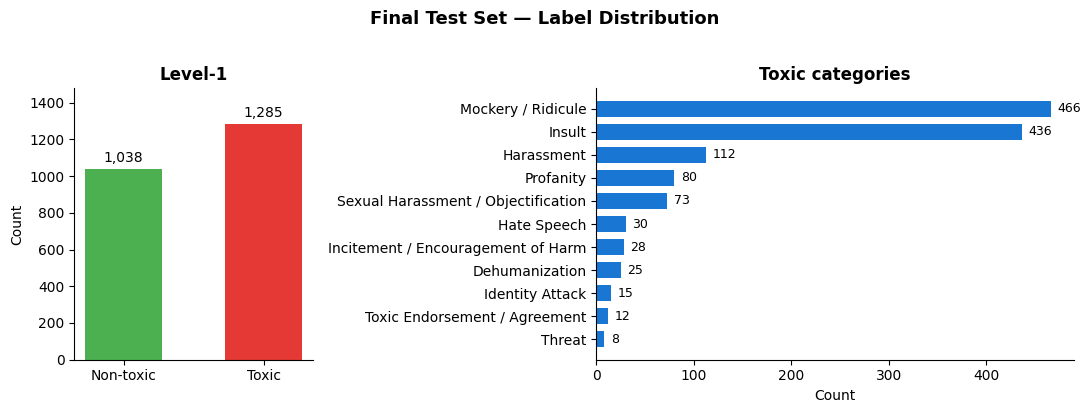

Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/figures/final_label_distribution_minimal.png


In [11]:
# =====================================================================
# Minimal clean figure (recommended)
# =====================================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 2]})

# ----- Left: Level-1 (শুধু ২টা bar) -----
l1 = combined["level_1_class"].value_counts().reindex(["Non-toxic", "Toxic"], fill_value=0)
axes[0].bar(
    ["Non-toxic", "Toxic"],
    l1.values,
    color=["#4CAF50", "#E53935"],
    width=0.55,
    edgecolor="none",
)
axes[0].set_title("Level-1", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Count")
axes[0].set_ylim(0, max(l1.values) * 1.15)
for i, v in enumerate(l1.values):
    axes[0].text(i, v + max(l1.values) * 0.03, f"{v:,}", ha="center", fontsize=10)
axes[0].spines["top"].set_visible(False)
axes[0].spines["right"].set_visible(False)

# ----- Right: Toxic categories (একই নীল shade, sorted) -----
tox = (
    combined.loc[combined["level_1_class"].eq("Toxic"), "toxicity_type"]
    .value_counts()
)
# শুধু যেগুলো আছে
tox = tox[tox > 0].sort_values(ascending=True)

axes[1].barh(tox.index, tox.values, color="#1976D2", edgecolor="none", height=0.7)
axes[1].set_title("Toxic categories", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Count")
for i, (lab, v) in enumerate(tox.items()):
    axes[1].text(v + max(tox.values) * 0.015, i, str(v), va="center", fontsize=9)
axes[1].spines["top"].set_visible(False)
axes[1].spines["right"].set_visible(False)

fig.suptitle("Final Test Set — Label Distribution", fontsize=13, fontweight="bold", y=1.02)
plt.tight_layout()
plt.savefig(FINAL_FIG_DIR / "final_label_distribution_minimal.png", dpi=300, bbox_inches="tight")
plt.show()
print("Saved ->", FINAL_FIG_DIR / "final_label_distribution_minimal.png")

## 8. Final integrity checks and gold export

In [12]:
FINAL_COLS = ["Source", "context", "reply", "level_1_class", "toxicity_type"]
final_gold = combined[FINAL_COLS].copy()
missing_context = int(final_gold["context"].astype(str).str.strip().eq("").sum())
missing_reply = int(final_gold["reply"].astype(str).str.strip().eq("").sum())
if missing_context or missing_reply:
    raise ValueError("Final dataset contains missing context/reply text.")
duplicate_item_identities = int(pd.Series([
    item_key(s,c,r) for s,c,r in zip(final_gold.Source, final_gold.context, final_gold.reply)
]).duplicated().sum())
assert duplicate_item_identities == 0
integrity = pd.DataFrame([{
    "pre_dedup_resolved_rows": pre_dedup_rows,
    "duplicate_rows_excluded": duplicates_removed,
    "rows": len(final_gold),
    "missing_context": missing_context,
    "missing_reply": missing_reply,
    "duplicate_exact_item_identities": duplicate_item_identities,
    "hierarchy_errors": 0,
    "first_round_majority_rows": int(combined["final_label_source"].eq("first_round_majority").sum()),
    "independent_round_majority_rows": int(combined["final_label_source"].eq("independent_round_majority").sum()),
    "pooled_6vote_fallback_rows": int(combined["final_label_source"].eq("pooled_first_plus_independent_votes").sum()),
}])
display(integrity)
write_csv(integrity, FINAL_AUDIT_DIR / "final_integrity_summary.csv")
final_provenance = combined[[
    "original_row_number","Source","context","reply","level_1_class",
    "toxicity_type","final_label_source","majority_vote_count","vote_pool_size",
    "vote_share","majority_pattern","resolution_method","blind_item_id"
]].copy()
assert len(final_provenance) == len(final_gold)
write_csv(final_gold, FINAL_RAW_PATH)
write_jsonl(final_gold, FINAL_JSONL_PATH)
write_csv(final_provenance, FINAL_PROVENANCE_PATH)
print("FINAL GOLD TEST SET CREATED:", len(final_gold), "rows")


,pre_dedup_resolved_rows,duplicate_rows_excluded,rows,missing_context,missing_reply,duplicate_exact_item_identities,hierarchy_errors,first_round_majority_rows,independent_round_majority_rows,pooled_6vote_fallback_rows
0,2329,6,2323,0,0,0,0,2136,186,1


Saved -> /content/drive/MyDrive/toxicity/final data/test/audit/final_integrity_summary.csv
Saved -> /content/drive/MyDrive/toxicity/final data/test/bangla_toxicity_test_set_HIERARCHICAL_FINAL.csv
Saved -> /content/drive/MyDrive/toxicity/final data/test/bangla_toxicity_test_set_HIERARCHICAL_FINAL.jsonl
Saved -> /content/drive/MyDrive/toxicity/final data/test/bangla_toxicity_test_set_HIERARCHICAL_FINAL_WITH_PROVENANCE.csv
FINAL GOLD TEST SET CREATED: 2323 rows


# Part B — Conservative preprocessing

Toxicity-relevant lexical and pragmatic signals are preserved.

The notebook does **not** remove:
- profanity;
- identity terms;
- negation;
- emojis;
- punctuation;
- repeated punctuation;
- slang;
- threat wording;
- ridicule/sarcasm cues.

In [13]:
ZERO_WIDTH_RE = re.compile(r"[\u200B-\u200D\u2060\uFEFF]")
URL_RE = re.compile(r"https?://\S+|www\.\S+", flags=re.IGNORECASE)
EMAIL_RE = re.compile(r"\b[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}\b")
MENTION_RE = re.compile(r"(?<!\w)@[A-Za-z0-9_]+")
SPACE_RE = re.compile(r"\s+")

def clean_text(x):
    x = "" if x is None else str(x)
    x = unicodedata.normalize("NFC", x)
    x = ZERO_WIDTH_RE.sub("", x)
    if NORMALIZE_URLS:
        x = URL_RE.sub(" <URL> ", x)
    if NORMALIZE_EMAILS:
        x = EMAIL_RE.sub(" <EMAIL> ", x)
    if NORMALIZE_MENTIONS:
        x = MENTION_RE.sub(" <USER> ", x)
    x = SPACE_RE.sub(" ", x).strip()
    return x

processed = final_gold.copy()
processed["context_clean"] = processed["context"].map(clean_text)
processed["reply_clean"] = processed["reply"].map(clean_text)
processed["model_text"] = (
    "[CTX] " + processed["context_clean"]
    + " [SEP] [REPLY] " + processed["reply_clean"]
)

processed["level_1_id"] = processed["level_1_class"].map(LEVEL1_TO_ID).astype(int)
processed["level_2_id"] = processed["toxicity_type"].map(LEVEL2_TO_ID).astype(int)
processed["level_2_toxic_id"] = (
    processed["toxicity_type"]
    .map(TOXIC_SUBTYPE_TO_ID)
    .fillna(-100)
    .astype(int)
)

processed["context_char_len"] = processed["context_clean"].str.len()
processed["reply_char_len"] = processed["reply_clean"].str.len()
processed["context_word_len"] = processed["context_clean"].str.split().str.len()
processed["reply_word_len"] = processed["reply_clean"].str.split().str.len()

write_csv(processed, FINAL_PROCESSED_PATH)
print("Processed test:", FINAL_PROCESSED_PATH)

Saved -> /content/drive/MyDrive/toxicity/final data/test/bangla_toxicity_test_set_HIERARCHICAL_FINAL_PROCESSED.csv
Processed test: /content/drive/MyDrive/toxicity/final data/test/bangla_toxicity_test_set_HIERARCHICAL_FINAL_PROCESSED.csv


# Part C — Q1/Data-in-Brief EDA

## 9. Final dataset overview and label distributions

In [14]:
overview = pd.DataFrame([{
    "dataset": "Final test set",
    "rows": len(final_gold),
    "non_toxic": int(final_gold["level_1_class"].eq("Non-toxic").sum()),
    "toxic": int(final_gold["level_1_class"].eq("Toxic").sum()),
    "missing_context": int(final_gold["context"].astype(str).str.strip().eq("").sum()),
    "missing_reply": int(final_gold["reply"].astype(str).str.strip().eq("").sum()),
    "exact_duplicate_item_identities": duplicate_item_identities,
    "duplicate_rows_excluded": duplicates_removed,
    "first_round_majority_rows": int(combined["final_label_source"].eq("first_round_majority").sum()),
    "independent_round_majority_rows": int(combined["final_label_source"].eq("independent_round_majority").sum()),
}])
display(overview)
write_csv(overview, FINAL_EDA_DIR / "dataset_overview.csv")

l1_dist = (
    final_gold["level_1_class"]
    .value_counts()
    .reindex(LEVEL1_LABELS, fill_value=0)
    .rename_axis("level_1_class")
    .reset_index(name="count")
)
l1_dist["percent"] = 100*l1_dist["count"]/len(final_gold)

l2_dist = (
    final_gold["toxicity_type"]
    .value_counts()
    .reindex(HIER_LABELS, fill_value=0)
    .rename_axis("toxicity_type")
    .reset_index(name="count")
)
l2_dist["percent_all"] = 100*l2_dist["count"]/len(final_gold)

toxic_n = max(int(final_gold["level_1_class"].eq("Toxic").sum()), 1)
l2_dist["percent_of_toxic"] = np.where(
    l2_dist["toxicity_type"].eq("None"),
    0,
    100*l2_dist["count"]/toxic_n
)

display(l1_dist)
display(l2_dist)
write_csv(l1_dist, FINAL_EDA_DIR / "level1_distribution.csv")
write_csv(l2_dist, FINAL_EDA_DIR / "level2_distribution.csv")


,dataset,rows,non_toxic,toxic,missing_context,missing_reply,exact_duplicate_item_identities,duplicate_rows_excluded,first_round_majority_rows,independent_round_majority_rows
0,Final test set,2323,1038,1285,0,0,0,6,2136,186


Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/dataset_overview.csv


,level_1_class,count,percent
0,Non-toxic,1038,44.683599
1,Toxic,1285,55.316401


,toxicity_type,count,percent_all,percent_of_toxic
0,None,1038,44.683599,0.000000
1,Insult,436,18.768833,33.929961
2,Threat,8,0.344382,0.622568
3,Hate Speech,30,1.291433,2.334630
4,Profanity,80,3.443823,6.225681
5,Harassment,112,4.821352,8.715953
6,Identity Attack,15,0.645717,1.167315
7,Toxic Endorsement / Agreement,12,0.516573,0.933852
8,Incitement / Encouragement of Harm,28,1.205338,2.178988
9,Mockery / Ridicule,466,20.060267,36.264591


Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/level1_distribution.csv
Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/level2_distribution.csv


## 10. Publication figures: Level-1, Level-2, source distribution

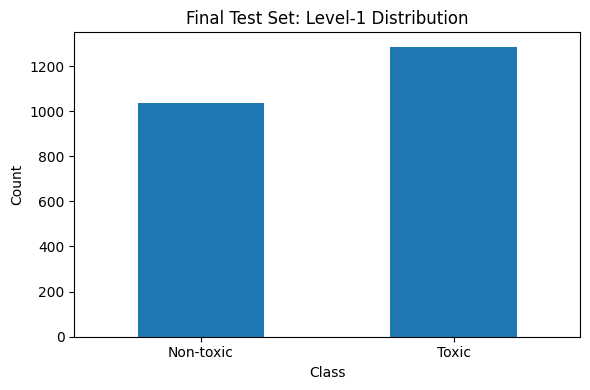

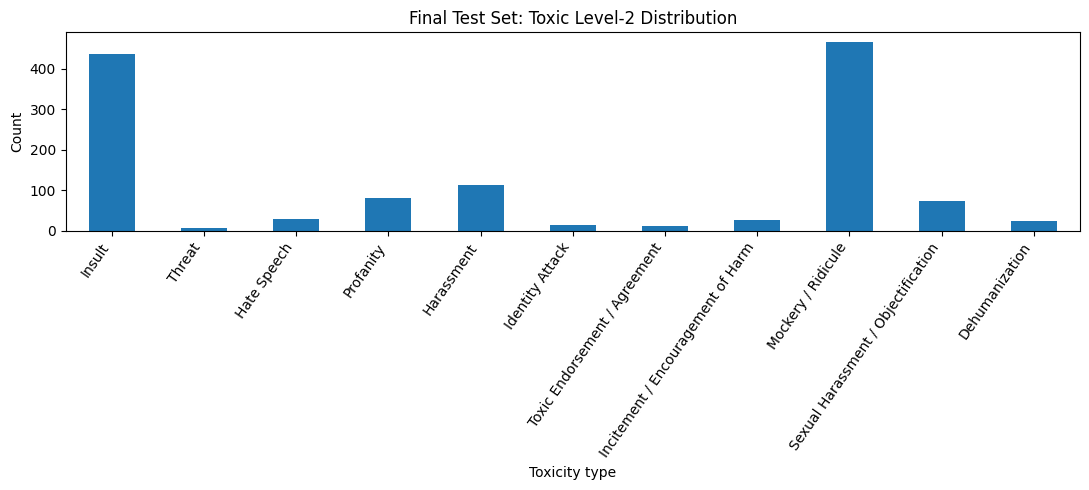

Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/source_distribution.csv


,Source,count,percent
0,facebook,982,42.272923
1,youtube,688,29.616875
2,news portal,653,28.110202


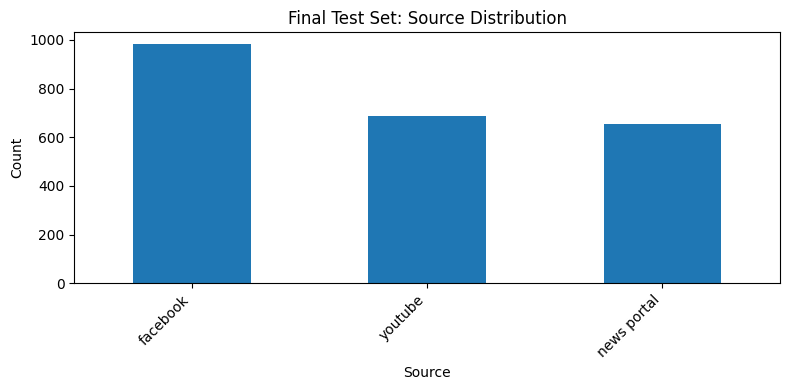

In [15]:
plt.figure(figsize=(6,4))
final_gold["level_1_class"].value_counts().reindex(LEVEL1_LABELS, fill_value=0).plot(kind="bar")
plt.title("Final Test Set: Level-1 Distribution")
plt.xlabel("Class")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(FINAL_FIG_DIR / "level1_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(11,5))
final_gold.loc[
    final_gold["level_1_class"].eq("Toxic"),
    "toxicity_type"
].value_counts().reindex(LEVEL2_LABELS, fill_value=0).plot(kind="bar")
plt.title("Final Test Set: Toxic Level-2 Distribution")
plt.xlabel("Toxicity type")
plt.ylabel("Count")
plt.xticks(rotation=55, ha="right")
plt.tight_layout()
plt.savefig(FINAL_FIG_DIR / "level2_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

source_dist = (
    final_gold["Source"]
    .value_counts(dropna=False)
    .rename_axis("Source")
    .reset_index(name="count")
)
source_dist["percent"] = 100*source_dist["count"]/len(final_gold)
write_csv(source_dist, FINAL_EDA_DIR / "source_distribution.csv")
display(source_dist)

plt.figure(figsize=(8,4))
source_dist.set_index("Source")["count"].plot(kind="bar")
plt.title("Final Test Set: Source Distribution")
plt.xlabel("Source")
plt.ylabel("Count")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.savefig(FINAL_FIG_DIR / "source_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

## 11. Source × label cross-tabulations

In [16]:
source_l1 = pd.crosstab(final_gold["Source"], final_gold["level_1_class"])
source_l2 = pd.crosstab(final_gold["Source"], final_gold["toxicity_type"])

display(source_l1)
display(source_l2)

write_csv(source_l1.reset_index(), FINAL_EDA_DIR / "source_by_level1.csv")
write_csv(source_l2.reset_index(), FINAL_EDA_DIR / "source_by_level2.csv")

level_1_class,Non-toxic,Toxic
Source,,
facebook,545,437
news portal,302,351
youtube,191,497


toxicity_type,Dehumanization,Harassment,Hate Speech,Identity Attack,Incitement / Encouragement of Harm,Insult,Mockery / Ridicule,None,Profanity,Sexual Harassment / Objectification,Threat,Toxic Endorsement / Agreement
Source,,,,,,,,,,,,
facebook,8,38,5,2,3,94,188,545,39,52,3,5
news portal,8,13,1,2,22,113,151,302,22,13,3,3
youtube,9,61,24,11,3,229,127,191,19,8,2,4


Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/source_by_level1.csv
Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/source_by_level2.csv


## 12. Text-length statistics and distributions

,feature,count,mean,std,min,50%,90%,95%,99%,max
0,context_char_len,2323.0,93.109772,58.504021,8.0,81.0,155.0,188.0,319.34,764.0
1,reply_char_len,2323.0,42.126560,51.769144,2.0,30.0,79.0,113.9,285.58,601.0
2,context_word_len,2323.0,14.975463,9.733432,2.0,13.0,25.0,31.0,55.78,142.0
3,reply_word_len,2323.0,7.690917,8.917800,1.0,6.0,14.0,20.0,49.56,96.0


Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/text_length_summary.csv


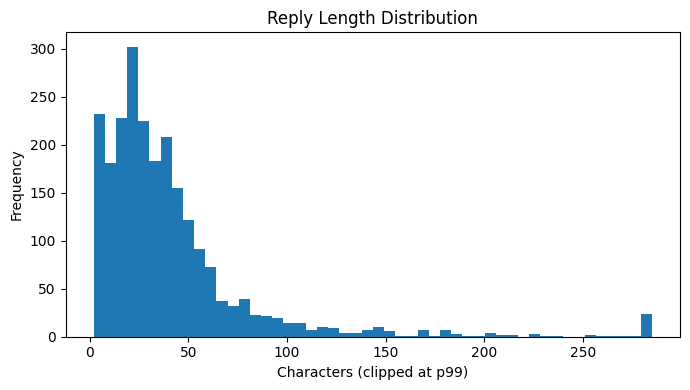

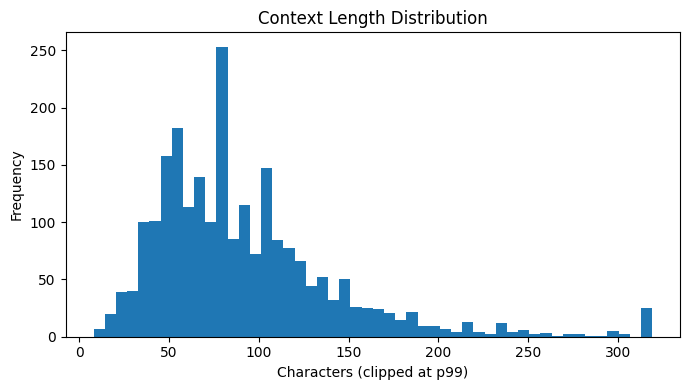

In [17]:
length_cols = [
    "context_char_len",
    "reply_char_len",
    "context_word_len",
    "reply_word_len",
]

length_summary = (
    processed[length_cols]
    .describe(percentiles=[0.50,0.90,0.95,0.99])
    .T
    .reset_index()
    .rename(columns={"index":"feature"})
)

display(length_summary)
write_csv(length_summary, FINAL_EDA_DIR / "text_length_summary.csv")

plt.figure(figsize=(7,4))
p99 = max(int(processed["reply_char_len"].quantile(0.99)), 1)
plt.hist(processed["reply_char_len"].clip(upper=p99), bins=50)
plt.title("Reply Length Distribution")
plt.xlabel("Characters (clipped at p99)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(FINAL_FIG_DIR / "reply_length_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(7,4))
p99c = max(int(processed["context_char_len"].quantile(0.99)), 1)
plt.hist(processed["context_char_len"].clip(upper=p99c), bins=50)
plt.title("Context Length Distribution")
plt.xlabel("Characters (clipped at p99)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.savefig(FINAL_FIG_DIR / "context_length_histogram.png", dpi=300, bbox_inches="tight")
plt.show()

## 13. Bengali/Latin script composition

In [18]:
BN_RE = re.compile(r"[\u0980-\u09FF]")
LATIN_RE = re.compile(r"[A-Za-z]")

def script_profile(text):
    text = str(text)
    bn = bool(BN_RE.search(text))
    lat = bool(LATIN_RE.search(text))
    if bn and lat:
        return "Bengali+Latin scripts"
    if bn:
        return "Bengali script only"
    if lat:
        return "Latin script only"
    return "Neither Bengali nor Latin letters"

pair_text = final_gold["context"].astype(str) + " " + final_gold["reply"].astype(str)
script_dist = (
    pair_text.map(script_profile)
    .value_counts()
    .rename_axis("script_profile")
    .reset_index(name="count")
)
script_dist["percent"] = 100*script_dist["count"]/len(final_gold)

display(script_dist)
write_csv(script_dist, FINAL_EDA_DIR / "script_profile_distribution.csv")

,script_profile,count,percent
0,Bengali script only,2252,96.943607
1,Bengali+Latin scripts,71,3.056393


Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/script_profile_distribution.csv


## 14. URL, mention, and supplementary-symbol prevalence

In [19]:
def has_url(x): return bool(URL_RE.search(str(x)))
def has_mention(x): return bool(MENTION_RE.search(str(x)))
def has_supp_symbol(x): return any(ord(ch) > 0xFFFF for ch in str(x))

pair_text = final_gold["context"].astype(str) + " " + final_gold["reply"].astype(str)

surface = pd.DataFrame([
    {
        "feature":"contains_url",
        "count":int(pair_text.map(has_url).sum()),
        "percent":100*pair_text.map(has_url).mean(),
    },
    {
        "feature":"contains_at_mention",
        "count":int(pair_text.map(has_mention).sum()),
        "percent":100*pair_text.map(has_mention).mean(),
    },
    {
        "feature":"contains_supplementary_unicode_symbol",
        "count":int(pair_text.map(has_supp_symbol).sum()),
        "percent":100*pair_text.map(has_supp_symbol).mean(),
    },
])

display(surface)
write_csv(surface, FINAL_EDA_DIR / "surface_feature_prevalence.csv")

,feature,count,percent
0,contains_url,3,0.129143
1,contains_at_mention,0,0.000000
2,contains_supplementary_unicode_symbol,248,10.675850


Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/surface_feature_prevalence.csv


## 15. Final-label provenance and majority strength

In [20]:
provenance = (
    combined["final_label_source"]
    .value_counts()
    .rename_axis("final_label_source")
    .reset_index(name="count")
)
provenance["percent"] = 100*provenance["count"]/len(combined)

majority_strength = (
    combined["majority_vote_count"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("majority_vote_count")
    .reset_index(name="count")
)

display(provenance)
display(majority_strength)

write_csv(provenance, FINAL_EDA_DIR / "final_label_provenance.csv")
write_csv(majority_strength, FINAL_EDA_DIR / "majority_strength_distribution.csv")

,final_label_source,count,percent
0,first_round_majority,2136,91.950065
1,independent_round_majority,186,8.006888
2,pooled_first_plus_independent_votes,1,0.043048


,majority_vote_count,count
0,2,675
1,3,1648


Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/final_label_provenance.csv
Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/majority_strength_distribution.csv


## 15A. Extended Data-in-Brief / Q1 EDA

The following analyses complement the basic distributions above and are intended for
dataset-paper reporting and supplementary material. They are generated from the final
gold/processed test data without modifying labels or removing rows.

Added analyses:

- class-wise context/reply length statistics;
- reply-length comparison by Level-1;
- subtype-wise reply-length boxplots;
- context-length vs reply-length association;
- source × Level-1 composition;
- detailed script/code-mixing and social-media feature prevalence;
- majority-strength visualization;
- preprocessing impact on text length;
- dataset construction/adjudication flow diagram;
- a consolidated EDA manifest.

In [21]:
# =========================
# Extended EDA helpers
# =========================

def _savefig(name):
    path = FINAL_FIG_DIR / name
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print("Saved figure:", path)
    return path

extended_figures = []
extended_tables = []

def _save_table(df, name):
    path = FINAL_TABLE_DIR / name
    write_csv(df, path)
    extended_tables.append(path)
    print("Saved table:", path)
    return path

In [22]:
# =========================
# Class-wise text-length statistics
# =========================

def summarize_length_by_group(frame, group_col):
    rows = []
    for group_name, g in frame.groupby(group_col, dropna=False):
        for feature in [
            "context_char_len",
            "context_word_len",
            "reply_char_len",
            "reply_word_len",
        ]:
            s = pd.to_numeric(g[feature], errors="coerce").dropna()
            rows.append({
                "group_column": group_col,
                "group": group_name,
                "feature": feature,
                "count": int(s.count()),
                "mean": float(s.mean()),
                "std": float(s.std()),
                "min": float(s.min()),
                "q25": float(s.quantile(0.25)),
                "median": float(s.median()),
                "q75": float(s.quantile(0.75)),
                "p90": float(s.quantile(0.90)),
                "p95": float(s.quantile(0.95)),
                "p99": float(s.quantile(0.99)),
                "max": float(s.max()),
            })
    return pd.DataFrame(rows)

length_by_l1 = summarize_length_by_group(processed, "level_1_class")
length_by_l2 = summarize_length_by_group(
    processed.loc[processed["level_1_class"].eq("Toxic")].copy(),
    "toxicity_type"
)

display(length_by_l1)
display(length_by_l2)

_save_table(length_by_l1, "length_statistics_by_level1.csv")
_save_table(length_by_l2, "length_statistics_by_level2_toxic.csv")

,group_column,group,feature,count,mean,std,min,q25,median,q75,p90,p95,p99,max
0,level_1_class,Non-toxic,context_char_len,1038,101.876686,59.925478,9.0,63.0,91.0,121.0,163.3,193.45,333.19,764.0
1,level_1_class,Non-toxic,context_word_len,1038,16.202312,10.178613,2.0,10.0,14.0,19.0,27.0,32.00,56.63,142.0
2,level_1_class,Non-toxic,reply_char_len,1038,28.410405,31.021739,2.0,12.0,23.0,39.0,52.0,61.15,123.89,601.0
3,level_1_class,Non-toxic,reply_word_len,1038,5.393064,5.224343,1.0,3.0,4.5,7.0,9.0,10.00,20.00,96.0
4,level_1_class,Toxic,context_char_len,1285,86.028016,56.365801,8.0,51.0,75.0,104.0,146.0,185.00,295.48,599.0
5,level_1_class,Toxic,context_word_len,1285,13.984436,9.244165,2.0,8.0,12.0,17.0,23.0,30.00,51.16,93.0
6,level_1_class,Toxic,reply_char_len,1285,53.206226,61.599149,2.0,22.0,36.0,60.0,101.6,147.80,353.92,565.0
7,level_1_class,Toxic,reply_word_len,1285,9.547082,10.679791,1.0,4.0,7.0,11.0,18.0,27.00,66.00,92.0


,group_column,group,feature,count,mean,std,min,q25,median,q75,p90,p95,p99,max
0,toxicity_type,Dehumanization,context_char_len,25,80.440000,39.091858,17.0,51.00,81.0,103.00,127.8,139.40,175.96,187.0
1,toxicity_type,Dehumanization,context_word_len,25,13.240000,6.166306,3.0,10.00,12.0,16.00,19.2,24.80,30.56,32.0
2,toxicity_type,Dehumanization,reply_char_len,25,62.160000,90.054465,15.0,20.00,35.0,68.00,85.6,162.00,392.80,460.0
3,toxicity_type,Dehumanization,reply_word_len,25,11.320000,16.188267,3.0,4.00,7.0,13.00,14.6,31.00,70.72,82.0
4,toxicity_type,Harassment,context_char_len,112,93.303571,70.574073,15.0,54.75,74.0,106.25,164.9,212.45,296.79,573.0
5,toxicity_type,Harassment,context_word_len,112,15.553571,11.761779,3.0,9.00,13.0,18.00,27.0,35.80,51.89,93.0
6,toxicity_type,Harassment,reply_char_len,112,84.785714,80.628659,6.0,34.75,62.5,101.50,147.9,214.45,426.27,444.0
7,toxicity_type,Harassment,reply_word_len,112,15.491071,14.270865,2.0,7.00,12.5,18.00,29.7,41.35,73.23,79.0
8,toxicity_type,Hate Speech,context_char_len,30,86.400000,59.969302,18.0,56.00,68.5,94.75,155.2,238.00,253.62,260.0
9,toxicity_type,Hate Speech,context_word_len,30,14.666667,9.245067,3.0,10.00,12.5,15.00,30.3,35.20,40.55,42.0


Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/tables/length_statistics_by_level1.csv
Saved table: /content/drive/MyDrive/toxicity/final data/test/eda_q1/tables/length_statistics_by_level1.csv
Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/tables/length_statistics_by_level2_toxic.csv
Saved table: /content/drive/MyDrive/toxicity/final data/test/eda_q1/tables/length_statistics_by_level2_toxic.csv


PosixPath('/content/drive/MyDrive/toxicity/final data/test/eda_q1/tables/length_statistics_by_level2_toxic.csv')

Saved figure: /content/drive/MyDrive/toxicity/final data/test/eda_q1/figures/reply_character_length_by_level1.png


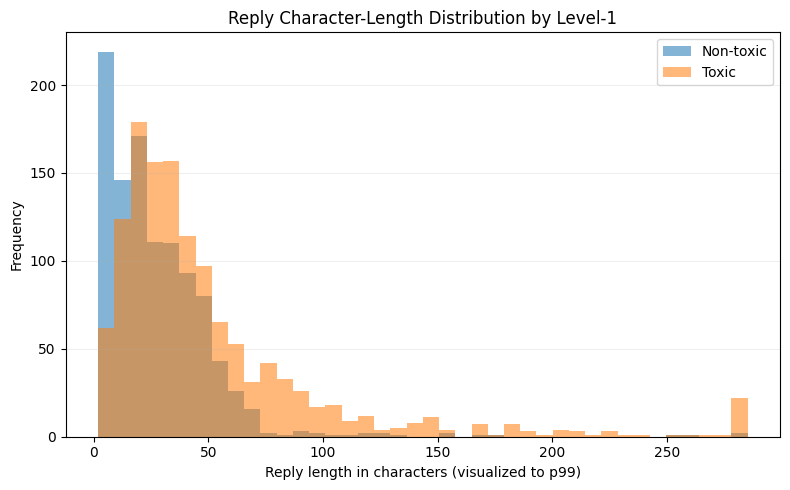

In [23]:
# =========================
# Reply character length by Level-1
# =========================

p99 = max(int(processed["reply_char_len"].quantile(0.99)), 1)

plt.figure(figsize=(8, 5))
for label in LEVEL1_LABELS:
    vals = processed.loc[
        processed["level_1_class"].eq(label),
        "reply_char_len"
    ].clip(upper=p99)
    plt.hist(vals, bins=40, alpha=0.55, label=label)

plt.title("Reply Character-Length Distribution by Level-1")
plt.xlabel("Reply length in characters (visualized to p99)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
p = _savefig("reply_character_length_by_level1.png")
extended_figures.append(p)
plt.show()

Saved figure: /content/drive/MyDrive/toxicity/final data/test/eda_q1/figures/reply_word_length_by_level1.png


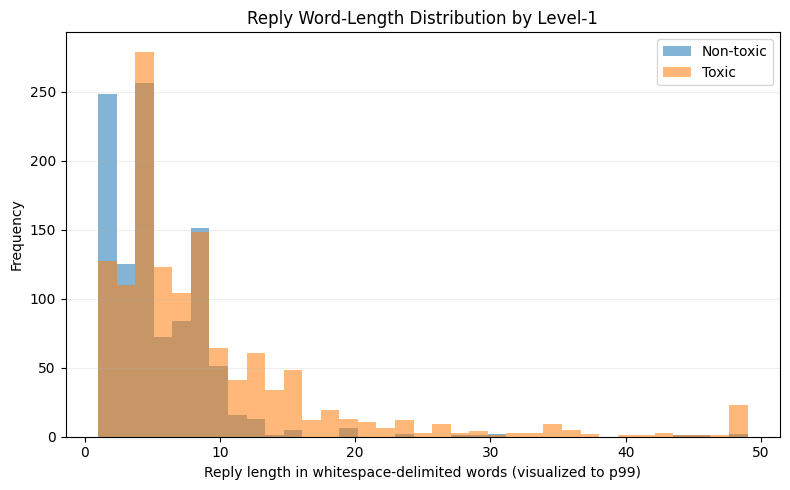

In [24]:
# =========================
# Reply word length by Level-1
# =========================

p99 = max(int(processed["reply_word_len"].quantile(0.99)), 1)

plt.figure(figsize=(8, 5))
for label in LEVEL1_LABELS:
    vals = processed.loc[
        processed["level_1_class"].eq(label),
        "reply_word_len"
    ].clip(upper=p99)
    plt.hist(vals, bins=35, alpha=0.55, label=label)

plt.title("Reply Word-Length Distribution by Level-1")
plt.xlabel("Reply length in whitespace-delimited words (visualized to p99)")
plt.ylabel("Frequency")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
p = _savefig("reply_word_length_by_level1.png")
extended_figures.append(p)
plt.show()

/tmp/ipykernel_7749/3902495176.py:24: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(box_data, labels=subtype_order, showfliers=False)


Saved figure: /content/drive/MyDrive/toxicity/final data/test/eda_q1/figures/reply_word_length_by_toxicity_subtype.png


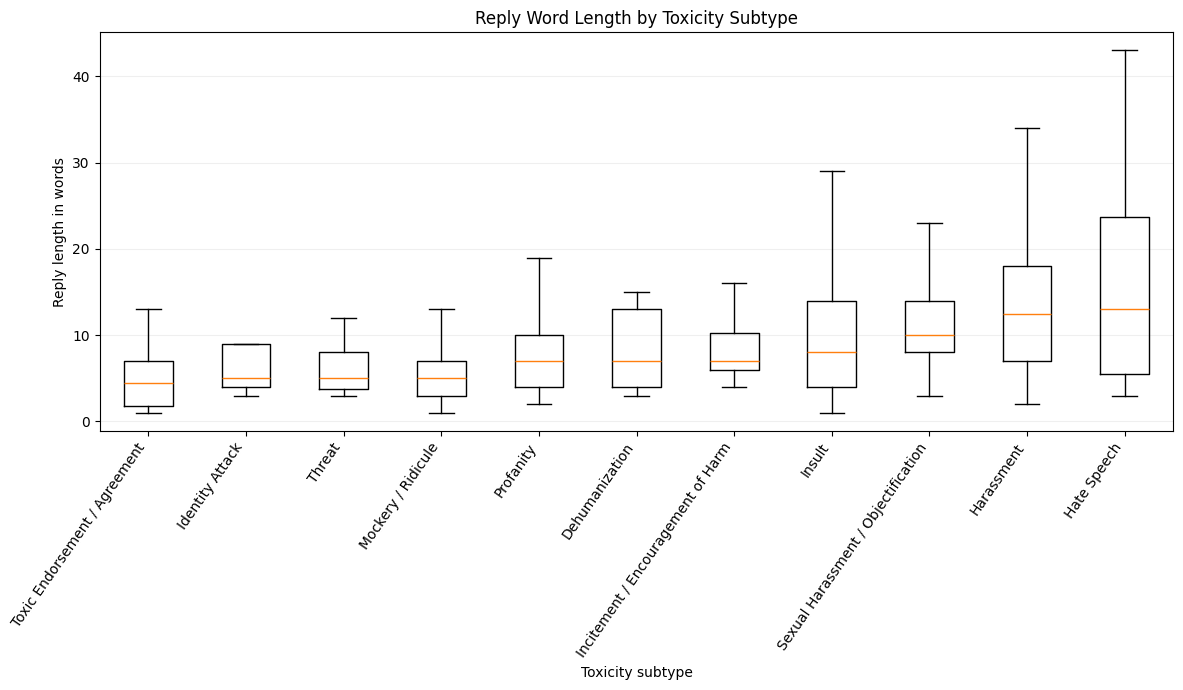

In [25]:
# =========================
# Toxic subtype-wise reply length
# =========================

toxic_processed = processed.loc[processed["level_1_class"].eq("Toxic")].copy()

subtype_order = (
    toxic_processed.groupby("toxicity_type")["reply_word_len"]
    .median()
    .sort_values()
    .index
    .tolist()
)

box_data = [
    toxic_processed.loc[
        toxic_processed["toxicity_type"].eq(label),
        "reply_word_len"
    ].to_numpy()
    for label in subtype_order
]

plt.figure(figsize=(12, 7))
plt.boxplot(box_data, labels=subtype_order, showfliers=False)
plt.title("Reply Word Length by Toxicity Subtype")
plt.xlabel("Toxicity subtype")
plt.ylabel("Reply length in words")
plt.xticks(rotation=55, ha="right")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
p = _savefig("reply_word_length_by_toxicity_subtype.png")
extended_figures.append(p)
plt.show()

Saved figure: /content/drive/MyDrive/toxicity/final data/test/eda_q1/figures/context_vs_reply_word_length.png


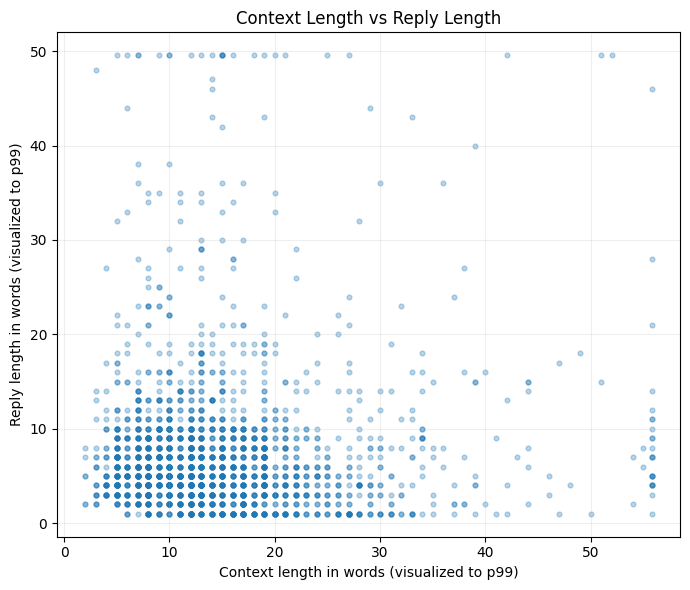

,pearson_context_reply_word_length,spearman_context_reply_word_length
0,0.035323,-0.08137


Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/tables/context_reply_length_correlation.csv
Saved table: /content/drive/MyDrive/toxicity/final data/test/eda_q1/tables/context_reply_length_correlation.csv


PosixPath('/content/drive/MyDrive/toxicity/final data/test/eda_q1/tables/context_reply_length_correlation.csv')

In [26]:
# =========================
# Context length vs reply length
# =========================

x = processed["context_word_len"].astype(float)
y = processed["reply_word_len"].astype(float)

x_cap = max(float(x.quantile(0.99)), 1.0)
y_cap = max(float(y.quantile(0.99)), 1.0)

plt.figure(figsize=(7, 6))
plt.scatter(
    x.clip(upper=x_cap),
    y.clip(upper=y_cap),
    s=12,
    alpha=0.30
)
plt.title("Context Length vs Reply Length")
plt.xlabel("Context length in words (visualized to p99)")
plt.ylabel("Reply length in words (visualized to p99)")
plt.grid(alpha=0.2)
plt.tight_layout()
p = _savefig("context_vs_reply_word_length.png")
extended_figures.append(p)
plt.show()

length_corr = pd.DataFrame([{
    "pearson_context_reply_word_length": float(
        processed[["context_word_len", "reply_word_len"]]
        .corr(method="pearson").iloc[0,1]
    ),
    "spearman_context_reply_word_length": float(
        processed[["context_word_len", "reply_word_len"]]
        .corr(method="spearman").iloc[0,1]
    ),
}])

display(length_corr)
_save_table(length_corr, "context_reply_length_correlation.csv")

level_1_class,Non-toxic,Toxic
Source,,
facebook,55.498982,44.501018
news portal,46.248086,53.751914
youtube,27.761628,72.238372


Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/tables/source_by_level1_percentage.csv
Saved table: /content/drive/MyDrive/toxicity/final data/test/eda_q1/tables/source_by_level1_percentage.csv
Saved figure: /content/drive/MyDrive/toxicity/final data/test/eda_q1/figures/source_level1_composition_percent.png


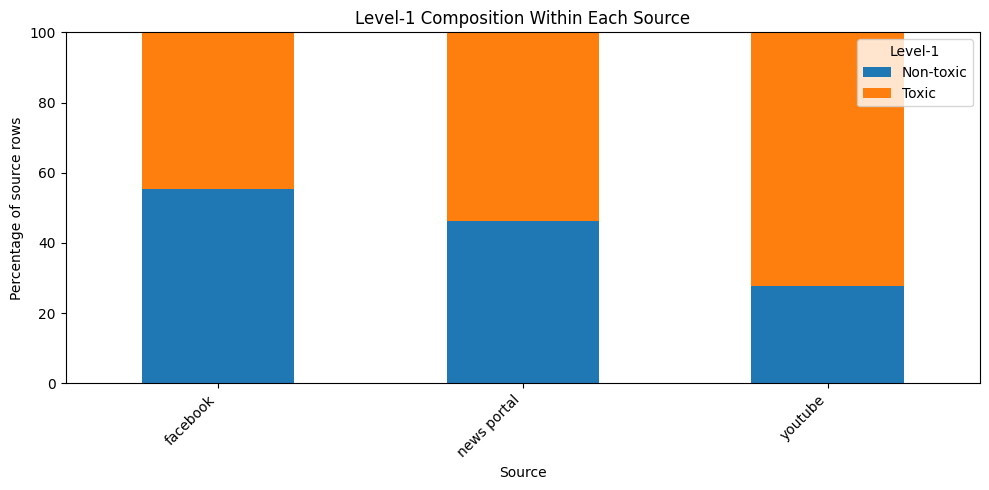

In [27]:
# =========================
# Source × Level-1 composition
# =========================

source_l1_pct = pd.crosstab(
    final_gold["Source"],
    final_gold["level_1_class"],
    normalize="index"
).reindex(columns=LEVEL1_LABELS, fill_value=0) * 100

display(source_l1_pct)
_save_table(
    source_l1_pct.reset_index(),
    "source_by_level1_percentage.csv"
)

ax = source_l1_pct.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 5)
)
ax.set_title("Level-1 Composition Within Each Source")
ax.set_xlabel("Source")
ax.set_ylabel("Percentage of source rows")
ax.set_ylim(0, 100)
plt.xticks(rotation=45, ha="right")
plt.legend(title="Level-1")
plt.tight_layout()
p = _savefig("source_level1_composition_percent.png")
extended_figures.append(p)
plt.show()

,text_field,feature,count,percent
0,context,contains_bengali_script,2319,99.827809
1,context,contains_latin_script,47,2.023246
2,context,bangla_latin_code_mixed,43,1.851055
3,context,contains_digit,452,19.457598
4,context,contains_url,3,0.129143
5,context,contains_at_mention,0,0.000000
6,context,contains_hashtag,0,0.000000
7,context,contains_emoji_or_symbol,185,7.963840
8,reply,contains_bengali_script,2321,99.913904
9,reply,contains_latin_script,28,1.205338


Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/tables/context_reply_text_feature_prevalence.csv
Saved table: /content/drive/MyDrive/toxicity/final data/test/eda_q1/tables/context_reply_text_feature_prevalence.csv
Saved figure: /content/drive/MyDrive/toxicity/final data/test/eda_q1/figures/context_reply_text_feature_prevalence.png


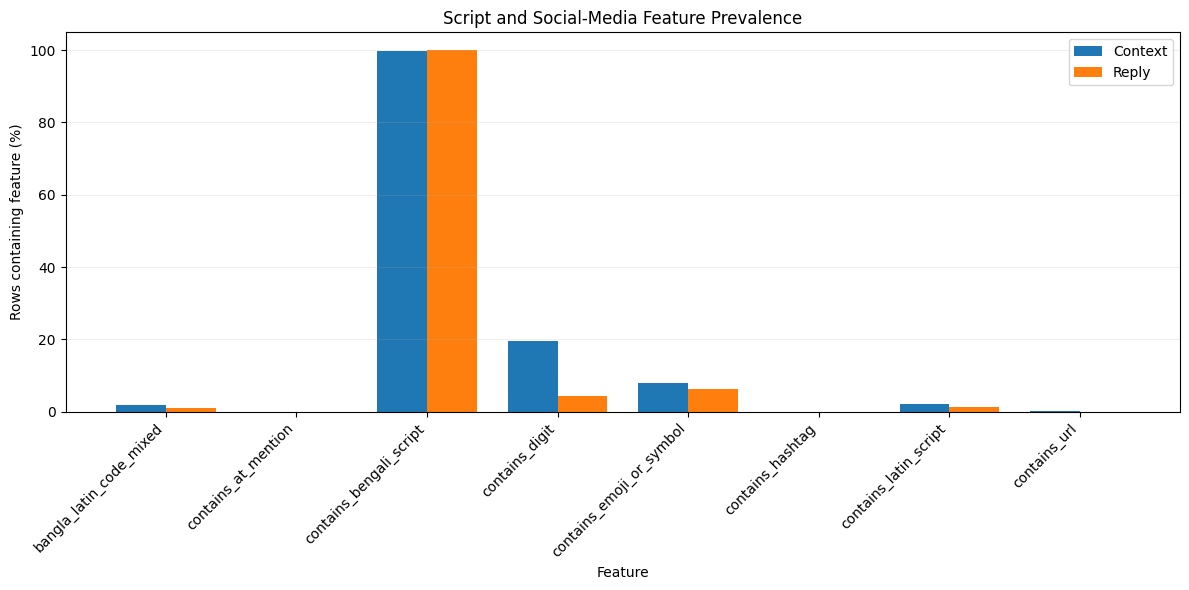

In [28]:
# =========================
# Detailed script/code-mixing and social-media features
# =========================

DIGIT_RE = re.compile(r"\d")
HASHTAG_RE = re.compile(r"(?<!\w)#\w+")
EMOJI_RE = re.compile(
    "["
    "\U0001F300-\U0001F5FF"
    "\U0001F600-\U0001F64F"
    "\U0001F680-\U0001F6FF"
    "\U0001F900-\U0001FAFF"
    "\u2600-\u27BF"
    "]"
)

def contains(pattern, text):
    return bool(pattern.search(str(text)))

def field_feature_summary(series, field_name):
    s = series.astype(str)
    bn = s.map(lambda x: contains(BN_RE, x))
    latin = s.map(lambda x: contains(LATIN_RE, x))
    rows = [
        ("contains_bengali_script", int(bn.sum())),
        ("contains_latin_script", int(latin.sum())),
        ("bangla_latin_code_mixed", int((bn & latin).sum())),
        ("contains_digit", int(s.map(lambda x: contains(DIGIT_RE, x)).sum())),
        ("contains_url", int(s.map(has_url).sum())),
        ("contains_at_mention", int(s.map(has_mention).sum())),
        ("contains_hashtag", int(s.map(lambda x: contains(HASHTAG_RE, x)).sum())),
        ("contains_emoji_or_symbol", int(s.map(lambda x: contains(EMOJI_RE, x)).sum())),
    ]
    out = pd.DataFrame(rows, columns=["feature", "count"])
    out.insert(0, "text_field", field_name)
    out["percent"] = 100 * out["count"] / len(s)
    return out

context_features = field_feature_summary(final_gold["context"], "context")
reply_features = field_feature_summary(final_gold["reply"], "reply")
text_features = pd.concat([context_features, reply_features], ignore_index=True)

display(text_features)
_save_table(text_features, "context_reply_text_feature_prevalence.csv")

wide = text_features.pivot(
    index="feature",
    columns="text_field",
    values="percent"
)

xpos = np.arange(len(wide))
width = 0.38

plt.figure(figsize=(12, 6))
plt.bar(xpos - width/2, wide["context"], width, label="Context")
plt.bar(xpos + width/2, wide["reply"], width, label="Reply")
plt.title("Script and Social-Media Feature Prevalence")
plt.xlabel("Feature")
plt.ylabel("Rows containing feature (%)")
plt.xticks(xpos, wide.index, rotation=45, ha="right")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
p = _savefig("context_reply_text_feature_prevalence.png")
extended_figures.append(p)
plt.show()

Saved figure: /content/drive/MyDrive/toxicity/final data/test/eda_q1/figures/final_label_provenance.png


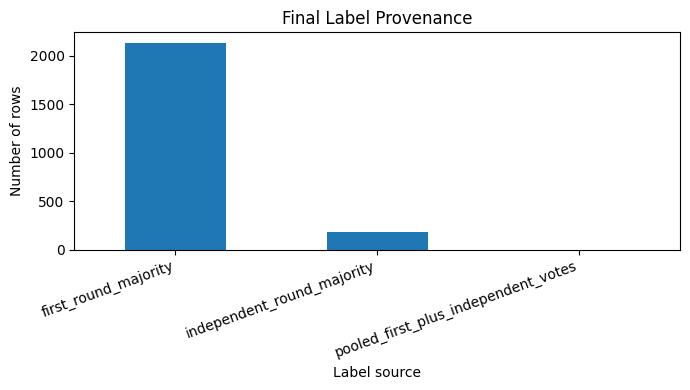

Saved figure: /content/drive/MyDrive/toxicity/final data/test/eda_q1/figures/majority_vote_strength.png


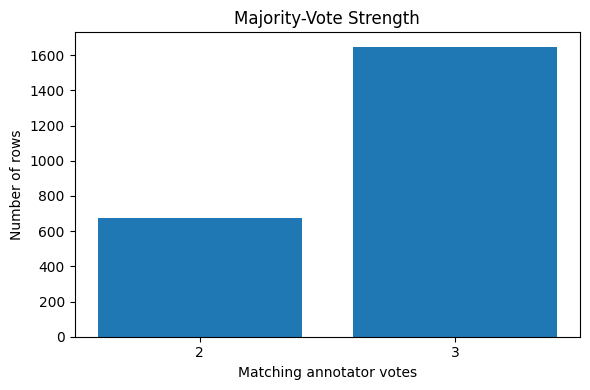

In [29]:
# =========================
# Majority strength and label provenance figures
# =========================

plt.figure(figsize=(7, 4))
prov_plot = provenance.set_index("final_label_source")["count"]
prov_plot.plot(kind="bar")
plt.title("Final Label Provenance")
plt.xlabel("Label source")
plt.ylabel("Number of rows")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
p = _savefig("final_label_provenance.png")
extended_figures.append(p)
plt.show()

plt.figure(figsize=(6, 4))
strength_plot = majority_strength.copy()
strength_plot["majority_vote_count"] = strength_plot["majority_vote_count"].astype(str)
plt.bar(strength_plot["majority_vote_count"], strength_plot["count"])
plt.title("Majority-Vote Strength")
plt.xlabel("Matching annotator votes")
plt.ylabel("Number of rows")
plt.tight_layout()
p = _savefig("majority_vote_strength.png")
extended_figures.append(p)
plt.show()

In [30]:
# =========================
# Conservative preprocessing impact
# =========================

preprocess_impact = pd.DataFrame([
    {
        "field": "context",
        "mean_raw_chars": float(final_gold["context"].astype(str).str.len().mean()),
        "mean_clean_chars": float(processed["context_clean"].astype(str).str.len().mean()),
        "median_raw_chars": float(final_gold["context"].astype(str).str.len().median()),
        "median_clean_chars": float(processed["context_clean"].astype(str).str.len().median()),
        "rows_changed": int(
            final_gold["context"].astype(str).ne(processed["context_clean"].astype(str)).sum()
        ),
    },
    {
        "field": "reply",
        "mean_raw_chars": float(final_gold["reply"].astype(str).str.len().mean()),
        "mean_clean_chars": float(processed["reply_clean"].astype(str).str.len().mean()),
        "median_raw_chars": float(final_gold["reply"].astype(str).str.len().median()),
        "median_clean_chars": float(processed["reply_clean"].astype(str).str.len().median()),
        "rows_changed": int(
            final_gold["reply"].astype(str).ne(processed["reply_clean"].astype(str)).sum()
        ),
    },
])

preprocess_impact["rows_changed_percent"] = (
    100 * preprocess_impact["rows_changed"] / len(final_gold)
)

display(preprocess_impact)
_save_table(preprocess_impact, "preprocessing_text_impact.csv")

,field,mean_raw_chars,mean_clean_chars,median_raw_chars,median_clean_chars,rows_changed,rows_changed_percent
0,context,92.112355,93.109772,80.0,81.0,1552,66.810159
1,reply,41.798967,42.126560,30.0,30.0,819,35.256134


Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/tables/preprocessing_text_impact.csv
Saved table: /content/drive/MyDrive/toxicity/final data/test/eda_q1/tables/preprocessing_text_impact.csv


PosixPath('/content/drive/MyDrive/toxicity/final data/test/eda_q1/tables/preprocessing_text_impact.csv')

Saved figure: /content/drive/MyDrive/toxicity/final data/test/eda_q1/figures/dataset_construction_workflow.png


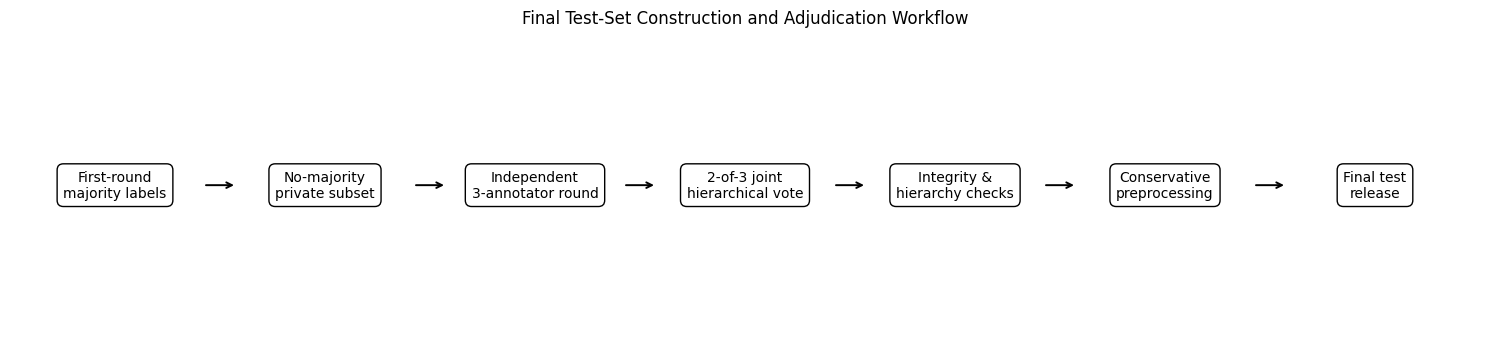

In [31]:
# =========================
# Dataset construction/adjudication workflow figure
# =========================

steps = [
    "First-round\nmajority labels",
    "No-majority\nprivate subset",
    "Independent\n3-annotator round",
    "2-of-3 joint\nhierarchical vote",
    "Integrity &\nhierarchy checks",
    "Conservative\npreprocessing",
    "Final test\nrelease",
]

plt.figure(figsize=(15, 3.6))
ax = plt.gca()
ax.set_xlim(0, len(steps))
ax.set_ylim(0, 1)
ax.axis("off")

for i, text in enumerate(steps):
    x = i + 0.5
    ax.text(
        x, 0.5, text,
        ha="center", va="center",
        bbox=dict(boxstyle="round,pad=0.45", fill=False)
    )
    if i < len(steps)-1:
        ax.annotate(
            "",
            xy=(i+1.08, 0.5),
            xytext=(i+0.92, 0.5),
            arrowprops=dict(arrowstyle="->", linewidth=1.4)
        )

plt.title("Final Test-Set Construction and Adjudication Workflow")
plt.tight_layout()
p = _savefig("dataset_construction_workflow.png")
extended_figures.append(p)
plt.show()

In [32]:
# =========================
# Consolidated extended-EDA manifest
# =========================

extended_eda_manifest = pd.DataFrame(
    [{"artifact_type": "figure", "path": str(p), "name": Path(p).name}
     for p in extended_figures]
    +
    [{"artifact_type": "table", "path": str(p), "name": Path(p).name}
     for p in extended_tables]
)

display(extended_eda_manifest)
write_csv(
    extended_eda_manifest,
    FINAL_EDA_DIR / "extended_eda_manifest.csv"
)

print("Extended figures:", len(extended_figures))
print("Extended tables :", len(extended_tables))
print("Figure folder   :", FINAL_FIG_DIR)
print("Table folder    :", FINAL_TABLE_DIR)

,artifact_type,path,name
0,figure,/content/drive/MyDrive/toxicity/final data/tes...,reply_character_length_by_level1.png
1,figure,/content/drive/MyDrive/toxicity/final data/tes...,reply_word_length_by_level1.png
2,figure,/content/drive/MyDrive/toxicity/final data/tes...,reply_word_length_by_toxicity_subtype.png
3,figure,/content/drive/MyDrive/toxicity/final data/tes...,context_vs_reply_word_length.png
4,figure,/content/drive/MyDrive/toxicity/final data/tes...,source_level1_composition_percent.png
5,figure,/content/drive/MyDrive/toxicity/final data/tes...,context_reply_text_feature_prevalence.png
6,figure,/content/drive/MyDrive/toxicity/final data/tes...,final_label_provenance.png
7,figure,/content/drive/MyDrive/toxicity/final data/tes...,majority_vote_strength.png
8,figure,/content/drive/MyDrive/toxicity/final data/tes...,dataset_construction_workflow.png
9,table,/content/drive/MyDrive/toxicity/final data/tes...,length_statistics_by_level1.csv


Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/extended_eda_manifest.csv
Extended figures: 9
Extended tables : 6
Figure folder   : /content/drive/MyDrive/toxicity/final data/test/eda_q1/figures
Table folder    : /content/drive/MyDrive/toxicity/final data/test/eda_q1/tables


## 16. Optional exact Train↔Test leakage audit

If `TRAIN_PATH` exists, exact normalized context+reply overlap is reported.

This cell does **not** remove data automatically.

In [33]:
train_path = Path(TRAIN_PATH)

if not train_path.exists():
    print("Optional Train file not found; leakage audit skipped.")
    print(train_path)
else:
    train = read_csv(train_path)
    context_col = "context" if "context" in train.columns else "previous_reply" if "previous_reply" in train.columns else None
    reply_col = "reply" if "reply" in train.columns else "target_reply" if "target_reply" in train.columns else None

    if context_col is None or reply_col is None:
        raise ValueError("Could not identify Train context/reply columns.")

    def pair_key(c, r):
        return hashlib.sha256(
            (normalize_text(c) + "\u241F" + normalize_text(r)).encode("utf-8")
        ).hexdigest()

    train_keys = pd.DataFrame({
        "train_row": np.arange(1, len(train)+1),
        "_pair_key": [pair_key(c,r) for c,r in zip(train[context_col], train[reply_col])]
    })

    test_keys = pd.DataFrame({
        "test_row": np.arange(1, len(final_gold)+1),
        "Source": final_gold["Source"],
        "context": final_gold["context"],
        "reply": final_gold["reply"],
        "_pair_key": [pair_key(c,r) for c,r in zip(final_gold["context"], final_gold["reply"])]
    })

    overlap = test_keys.merge(train_keys, on="_pair_key", how="inner")
    print("Exact Train↔Test overlaps:", len(overlap))
    write_csv(overlap, FINAL_AUDIT_DIR / "train_test_exact_overlap.csv")

Optional Train file not found; leakage audit skipped.
/content/drive/MyDrive/toxicity/final data/train/bangla_context_toxicity_train_LEVEL1_BALANCED_1TO1.csv


## 17. Data dictionary

In [34]:
data_dictionary = pd.DataFrame([
    {"variable":"Source","file":"raw + processed","type":"categorical string","description":"Source/platform category for the context-reply item."},
    {"variable":"context","file":"raw + processed","type":"UTF-8 string","description":"Previous comment/conversational context."},
    {"variable":"reply","file":"raw + processed","type":"UTF-8 string","description":"Target reply assigned the hierarchical toxicity label."},
    {"variable":"level_1_class","file":"raw + processed","type":"categorical","description":"Non-toxic or Toxic."},
    {"variable":"toxicity_type","file":"raw + processed","type":"categorical","description":"None for Non-toxic; otherwise one of 11 toxic subtypes."},
    {"variable":"context_clean","file":"processed","type":"UTF-8 string","description":"Conservatively normalized context."},
    {"variable":"reply_clean","file":"processed","type":"UTF-8 string","description":"Conservatively normalized reply."},
    {"variable":"model_text","file":"processed","type":"UTF-8 string","description":"[CTX] context [SEP] [REPLY] reply."},
    {"variable":"level_1_id","file":"processed","type":"integer","description":"0=Non-toxic, 1=Toxic."},
    {"variable":"level_2_id","file":"processed","type":"integer","description":"12-class hierarchical ID."},
    {"variable":"level_2_toxic_id","file":"processed","type":"integer","description":"Toxic subtype ID; Non-toxic rows use -100."},
])
display(data_dictionary)
write_csv(data_dictionary, FINAL_EDA_DIR / "data_dictionary.csv")

,variable,file,type,description
0,Source,raw + processed,categorical string,Source/platform category for the context-reply...
1,context,raw + processed,UTF-8 string,Previous comment/conversational context.
2,reply,raw + processed,UTF-8 string,Target reply assigned the hierarchical toxicit...
3,level_1_class,raw + processed,categorical,Non-toxic or Toxic.
4,toxicity_type,raw + processed,categorical,None for Non-toxic; otherwise one of 11 toxic ...
5,context_clean,processed,UTF-8 string,Conservatively normalized context.
6,reply_clean,processed,UTF-8 string,Conservatively normalized reply.
7,model_text,processed,UTF-8 string,[CTX] context [SEP] [REPLY] reply.
8,level_1_id,processed,integer,"0=Non-toxic, 1=Toxic."
9,level_2_id,processed,integer,12-class hierarchical ID.


Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/data_dictionary.csv


## 18. Reproducibility manifest and hashes

In [35]:
input_paths = {
    "first_majority_clean": FIRST_CLEAN_PATH,
    "first_majority_audit": FIRST_AUDIT_PATH,
    "private_no_majority_mapping": PRIVATE_MAP_PATH,
}
for f in INDEPENDENT_FILES:
    input_paths[f] = INDEPENDENT_DIR / f

manifest = {
    "created_utc": datetime.now(timezone.utc).isoformat(),
    "seed": SEED,
    "python": platform.python_version(),
    "final_rows": int(len(final_gold)),
    "pre_dedup_resolved_rows": int(pre_dedup_rows),
    "duplicate_rows_excluded": int(duplicates_removed),
    "deduplication_key": "NFC normalized Source+context+reply; stop on conflicting hierarchy labels",
    "majority_rule": "2-of-3 identical joint hierarchical label",
    "level1_labels": LEVEL1_LABELS,
    "level2_labels": HIER_LABELS,
    "preprocessing": {
        "unicode_nfc": True,
        "remove_zero_width": True,
        "url_placeholder": NORMALIZE_URLS,
        "email_placeholder": NORMALIZE_EMAILS,
        "mention_placeholder": NORMALIZE_MENTIONS,
        "stopword_removal": False,
        "punctuation_removal": False,
        "emoji_removal": False,
        "stemming": False,
        "lemmatization": False,
    },
    "input_sha256": {
        k: sha256_file(v)
        for k,v in input_paths.items()
        if Path(v).exists()
    },
    "output_sha256": {
        FINAL_RAW_PATH.name: sha256_file(FINAL_RAW_PATH),
        FINAL_JSONL_PATH.name: sha256_file(FINAL_JSONL_PATH),
        FINAL_PROVENANCE_PATH.name: sha256_file(FINAL_PROVENANCE_PATH),
        FINAL_PROCESSED_PATH.name: sha256_file(FINAL_PROCESSED_PATH),
    },
}

with open(FINAL_TEST_DIR / "manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)

with open(FINAL_PREPROCESS_DIR / "label_maps.json", "w", encoding="utf-8") as f:
    json.dump({
        "level1_to_id": LEVEL1_TO_ID,
        "level2_to_id": LEVEL2_TO_ID,
        "toxic_subtype_to_id": TOXIC_SUBTYPE_TO_ID,
        "non_toxic_toxic_subtype_mask": -100,
    }, f, ensure_ascii=False, indent=2)

print("Manifest saved.")


Manifest saved.


## 19. Publication summary

In [36]:
publication_summary = pd.DataFrame([
    {"measure":"Final test rows","value":len(final_gold)},
    {"measure":"First-round majority rows","value":int(combined["final_label_source"].eq("first_round_majority").sum())},
    {"measure":"Independent-round majority rows","value":int(combined["final_label_source"].eq("independent_round_majority").sum())},
    {"measure":"Pooled first+independent 6-vote fallback rows","value":int(combined["final_label_source"].eq("pooled_first_plus_independent_votes").sum())},
    {"measure":"Non-toxic rows","value":int(final_gold["level_1_class"].eq("Non-toxic").sum())},
    {"measure":"Toxic rows","value":int(final_gold["level_1_class"].eq("Toxic").sum())},
    {"measure":"Exact duplicate identities remaining","value":duplicate_item_identities},
    {"measure":"Duplicate records excluded after annotation","value":duplicates_removed},
])
display(publication_summary)
write_csv(publication_summary, FINAL_EDA_DIR / "publication_summary_table.csv")


,measure,value
0,Final test rows,2323
1,First-round majority rows,2136
2,Independent-round majority rows,186
3,Pooled first+independent 6-vote fallback rows,1
4,Non-toxic rows,1038
5,Toxic rows,1285
6,Exact duplicate identities remaining,0
7,Duplicate records excluded after annotation,6


Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/publication_summary_table.csv


## 20. Output structure

After a successful complete run:

```text
MyDrive/toxicity/
├── test set/
│   ├── annotator/
│   │   ├── THREE_ANNOTATOR_MAJORITY_RESOLVED.csv
│   │   └── iaa_results/
│   │       ├── THREE_ANNOTATOR_MAJORITY_WITH_AUDIT.csv
│   │       └── NO_MAJORITY_PRIVATE_AUDIT.csv
│   └── independently annotate/
│       ├── independent1.csv
│       ├── independent2.csv
│       ├── independent3.csv
│       └── no majority next round/
│           └── ROUND2_NO_MAJORITY_FOR_NEXT_ANNOTATORS.csv   # only if needed
│
└── final data/
    └── test/
        ├── bangla_toxicity_test_set_HIERARCHICAL_FINAL.csv
        ├── bangla_toxicity_test_set_HIERARCHICAL_FINAL.jsonl
        ├── bangla_toxicity_test_set_HIERARCHICAL_FINAL_WITH_PROVENANCE.csv
        ├── bangla_toxicity_test_set_HIERARCHICAL_FINAL_PROCESSED.csv
        ├── manifest.json
        ├── audit/
        ├── preprocessing/
        ├── independent_round/
        └── eda_q1/
            ├── figures/
            └── tables/
```

### Reporting note

For a data paper, report:

- first-round annotation and IAA;
- the number of no-majority items sent for independent re-annotation;
- independent-round IAA separately because it is a difficult subset;
- the exact 2-of-3 joint-majority rule;
- the number of final labels coming from each annotation stage;
- preprocessing and quality-control procedures;
- duplicate exclusions (with retained audit CSV), leakage audits and descriptive dataset statistics.

### Extended EDA now includes

- Level-1 and Level-2 distributions;
- source distribution and source × label composition;
- overall and class-wise text-length statistics;
- reply character/word distributions by Level-1;
- toxicity-subtype reply-length boxplots;
- context↔reply length correlation;
- Bengali/Latin/code-mixed text statistics;
- URL, mention, hashtag, digit and emoji/symbol prevalence;
- final-label provenance and majority-vote strength;
- conservative preprocessing impact;
- dataset-construction workflow figure;
- machine-readable EDA artifact manifest.


### Pooled fallback audit files

The enhanced finalization also writes:

- `final data/test/independent_round/independent_plus_pooled6_resolved.csv`
- `final data/test/independent_round/pooled_6vote_fallback_audit.csv`

For publication, distinguish:

- independent-round strict majority;
- pooled six-vote **absolute majority**;
- pooled six-vote **unique plurality**.

Do not describe a 2/6 or 3/6 unique plurality as a mathematical majority.


In [37]:
MASK_PATH = "/content/bangladesh_mask.png"

In [38]:
 !pip install -q wordcloud
#Download a Bangla font once:
!wget -q -O /content/NotoSansBengali.ttf \
  "https://github.com/googlefonts/noto-fonts/raw/main/hinted/ttf/NotoSansBengali/NotoSansBengali-Regular.ttf"

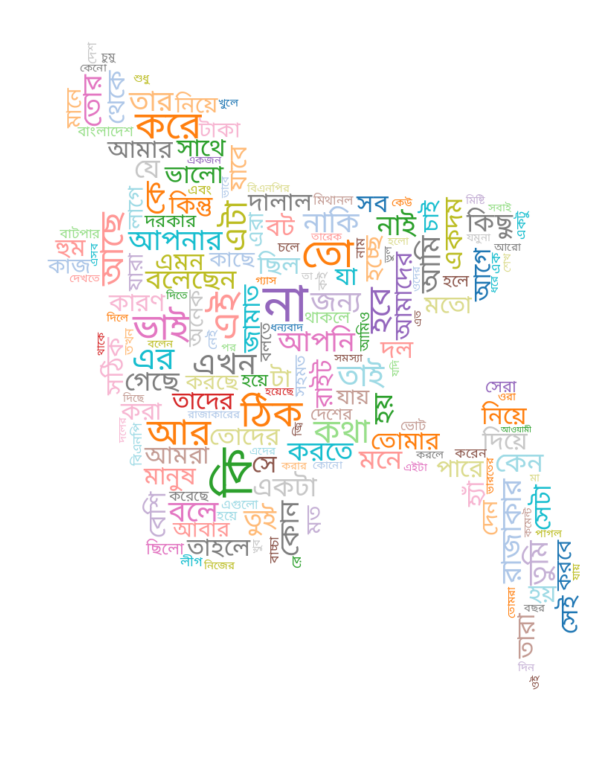

Saved -> /content/drive/MyDrive/toxicity/final data/test/eda_q1/figures/final_bd_shaped_wordcloud_mixed.png


In [39]:
# !pip install -q wordcloud
# !wget -q -O /content/NotoSansBengali.ttf \
#   "https://github.com/googlefonts/noto-fonts/raw/main/hinted/ttf/NotoSansBengali/NotoSansBengali-Regular.ttf"

import re
import requests
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.path import Path
from collections import Counter
from wordcloud import WordCloud

FONT = "/content/NotoSansBengali.ttf"
TOKEN_RE = re.compile(r"[\u0980-\u09FF]+|[A-Za-z]+")

# ----- Bangladesh mask -----
url = "https://raw.githubusercontent.com/johan/world.geo.json/master/countries/BGD.geo.json"
data = requests.get(url, timeout=30).json()

def rings_from_geom(geom):
    if geom["type"] == "Polygon":
        return [geom["coordinates"][0]]
    if geom["type"] == "MultiPolygon":
        return [p[0] for p in geom["coordinates"]]
    return []

rings = []
feats = data["features"] if data.get("type") == "FeatureCollection" else [data]
for f in feats:
    rings.extend(rings_from_geom(f["geometry"]))

pts = np.vstack([np.asarray(r) for r in rings])
minx, miny = pts.min(axis=0)
maxx, maxy = pts.max(axis=0)

# paper-এর মতো height/width ratio
W, H = 800, 1000
pad = 0.04
xs = np.linspace(minx - (maxx - minx) * pad, maxx + (maxx - minx) * pad, W)
ys = np.linspace(maxy + (maxy - miny) * pad, miny - (maxy - miny) * pad, H)
xx, yy = np.meshgrid(xs, ys)
points = np.column_stack([xx.ravel(), yy.ravel()])

inside = np.zeros(H * W, dtype=bool)
for ring in rings:
    inside |= Path(ring).contains_points(points)
inside = inside.reshape(H, W)

mask = np.full((H, W), 255, dtype=np.uint8)
mask[inside] = 0

# soft edge (paper-এর মতো মসৃণ)
from scipy import ndimage
mask_soft = mask.copy()
# keep hard mask for wordcloud; soft only if needed

# ----- mixed Toxic + Non-toxic -----
freq = Counter()
for t in combined["reply"].astype(str):
    for w in TOKEN_RE.findall(t.lower()):
        if len(w) >= 2:
            freq[w] += 1

wc = WordCloud(
    width=W,
    height=H,
    background_color="white",
    mask=mask,
    contour_width=0,              # paper-এ border line নেই
    font_path=FONT,
    colormap="tab20",             # multi-color like paper
    max_words=180,
    max_font_size=70,
    min_font_size=8,
    relative_scaling=0.4,
    collocations=False,
    prefer_horizontal=0.65,
    repeat=False,
    regexp=r"[\u0980-\u09FF]+|[A-Za-z]+",
).generate_from_frequencies(freq)

plt.figure(figsize=(6, 7.5), facecolor="white")
plt.imshow(wc, interpolation="bilinear")
plt.axis("off")
plt.tight_layout(pad=0.2)
plt.savefig(
    FINAL_FIG_DIR / "final_bd_shaped_wordcloud_mixed.png",
    dpi=300, bbox_inches="tight", facecolor="white", pad_inches=0.05,
)
plt.show()
print("Saved ->", FINAL_FIG_DIR / "final_bd_shaped_wordcloud_mixed.png")